One-Dimentional Solver: We solve the ROF functional on the line
(0,1) using primal-dual iteration.

We initalize the grid and $g$, and choose our initial guesses $u^{(0)}$ and $p^{(0)}$, defaulted to $u^{(0)} = \int g$ and $p^{(0)} = 0$. All functions are represented as numpy arrays

In [ ]:
import numpy as np
import torch

def get_g(N, noise=0):
    """
    returns numpy array of length N giving the cell averages of g
    """
    temp = np.linspace(0, 1, N) - 1/2
    return np.heaviside(temp, 1) + np.random.normal(0, noise, N)

def get_u0(N):
    """
    returns numpy array of length N + 1 giving u^(0) at nodal values
    """
    return np.full(N+1, np.mean(get_g(N)))

def get_p0(N):
    """
    returns numpy array of length N giving p^(0)
    """
    return np.zeros(N)

We now implement the $(\cdot,\cdot)_{h,s}$ inner product, noting that the finite elements are uniquely represented by their vector of nodal values. We then build the stiffness matrix $A^{h,s}_{ij} = (\phi_{i}, \phi_{j})_{h,s}$ where $\phi_{i}$ is the nodal basis. We also build $B_{ij} = (\phi_{i}, \phi_{j})$, $K_{i} = (p, \nabla \phi_{i})$, and $C_{ij} = (\phi_{i}, \psi_{j})$.

In [ ]:
import torch
import numpy as np

def IP(X, Y, s=-1):
    """
    X, Y are N+1 dimensional PyTorch tensors of nodal values
    s = -1 gives L^2 norm
    s \neq 0 gives L^2 + h^{s} H_{0}^{1} norm
    """
    device = X.device
    N = len(X) - 1
    h = 1.0 / N

    X_i = X[:-1]
    X_next = X[1:]
    Y_i = Y[:-1]
    Y_next = Y[1:]

    dX = X_next - X_i
    dY = Y_next - Y_i

    # L2 inner product
    L2 = torch.sum(h * X_i * Y_i + (h**2 / 2) * dX * Y_i + (h**2 / 2) * dY * X_i + (h**3 / 3) * dX * dY)

    # weighted H1 semi-norm
    if s != -1:
        H1 = torch.sum(dX * dY) * (h**(s-1))
    else:
        H1 = 0.0

    return L2 + H1

def grad(X):
    """
    inputs X in P^{1}, a tensor of length N+1, and outputs \nabla X in P^{0}, a tensor of length N
    """
    return (X[1:] - X[:-1]) * (len(X) - 1)

def get_A(N, s=-1, device='cpu'):
    """
    A is (N+1) x (N+1) computed by (phi_i, phi_j)_{h,s}
    """
    phi_1 = torch.zeros(N+1, dtype=torch.float64, device=device)
    phi_2 = torch.zeros(N+1, dtype=torch.float64, device=device)
    phi_1[1] = 1
    phi_2[2] = 1
    a = IP(phi_1, phi_1, s).item()
    b = IP(phi_1, phi_2, s).item()

    A = torch.zeros((N+1, N+1), dtype=torch.float64, device=device)
    A.fill_diagonal_(b)
    A.diagonal().fill_(a)
    A[0, 0] = a / 2
    A[-1, -1] = a / 2

    # Re-apply diagonal offsets manually in PyTorch
    for i in range(N):
        A[i+1, i] = b
        A[i, i+1] = b
    return A

def get_K(N, device='cpu'):
    """
    returns the N+1 x N matrix (\nabla phi_i, psi_j)
    """
    K = torch.zeros((N+1, N), dtype=torch.float64, device=device)
    K.diagonal().fill_(-1.0)
    for i in range(N):
        K[i+1, i] = 1.0
    return K

def get_C(N, device='cpu'):
    """
    returns the N+1 x N matrix (phi_i, psi_j)
    """
    C = torch.zeros((N+1, N), dtype=torch.float64, device=device)
    C.diagonal().fill_(1.0 / (2 * N))
    for i in range(N):
        C[i+1, i] = 1.0 / (2 * N)
    return C

We now implement the matrix solver which returns $u^{(k+1)}, d_{t}u^{(k+1)}, p^{(k+1)}$. We note that $u^{(k+1)}$ are length $N+1$ vectors of nodal values, while $p^{(k+1)}$ are length $N$ vectors of interior values. We then iterate this solver to give the optimizer.

In [ ]:
import torch
import numpy as np

def Mat_Solver(uk, duk, pk, T, alpha, g, A, B, C, K, s=-1):
    """
    Solves one primal-dual iteration step in 1D using PyTorch (GPU/CPU).
    """
    device = uk.device
    N = len(pk)
    u_tilde = uk + T * duk
    p_next = (pk + T * grad(u_tilde))
    p_next = p_next / torch.maximum(torch.ones_like(p_next), torch.abs(p_next))

    S1 = torch.mv(-K, p_next)
    S2 = torch.mv(-alpha * B, uk)
    S3 = torch.mv(alpha * C, g)
    rhs = S1 + S2 + S3

    # Solve linear system using PyTorch PyTorch solver
    lhs_matrix = A + alpha * T * B
    du_next = torch.linalg.solve(lhs_matrix, rhs)
    u_next = uk + du_next * T
    return p_next, du_next, u_next

def Solve(N, alpha, T, noise=0, s=1, eps_stop=1e-8, max_its=2000):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    A = get_A(N, s, device=device)
    B = get_A(N, -1, device=device)
    C = get_C(N, device=device)
    K = get_K(N, device=device)
    g = torch.tensor(get_g(N, noise), dtype=torch.float64, device=device)

    u_next = torch.full((N+1,), np.mean(g.cpu().numpy()), dtype=torch.float64, device=device)
    p_next = torch.zeros(N, dtype=torch.float64, device=device)
    du_next = torch.zeros(N+1, dtype=torch.float64, device=device)

    res = 1.0 + eps_stop
    residuals = []
    num_iter = 0

    while res > eps_stop and num_iter < max_its:
        uk, duk, pk = u_next, du_next, p_next
        p_next, du_next, u_next = Mat_Solver(uk, duk, pk, T, alpha, g, A, B, C, K, s)
        res = torch.sqrt(IP(du_next, du_next, s)).item()
        residuals.append(res)
        num_iter += 1

    if num_iter == max_its:
        print("Warning: Max iterations reached")

    return u_next.cpu().numpy(), p_next.cpu().numpy(), residuals, num_iter, g.cpu().numpy()

### Example One:

Let g be the indicator function on [1/2,1]. Let's build a solver to approximate $g$.

Final Residual 0.0000000086
Iterations Requires 706


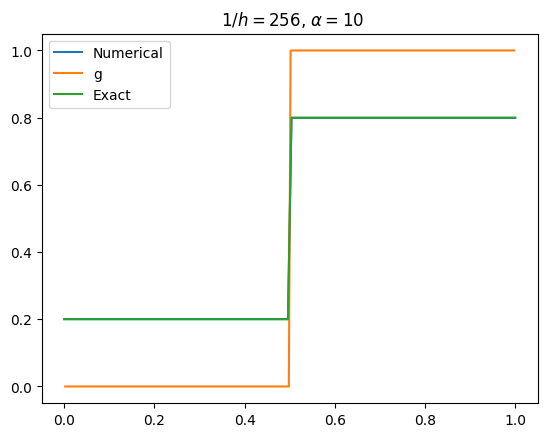

In [ ]:
import matplotlib.pyplot as plt
N = 256
alpha = 10
T = .9*np.sqrt((1/N))
u, p, residuals, num_iter, g = Solve(N,alpha,T, s=1)
print(f"Final Residual {residuals[-1]:.10f}")
print(f"Iterations Requires {num_iter}")
X = np.linspace(0,1,N+1)
Y = np.linspace(0,1, N, endpoint = False) + (1/(2*N))
plt.plot(X,u, label= "Numerical")
plt.plot(Y,g, label = "g")

if alpha <= 4:
  exact = np.ones(N+1) * 1/2
else:
  exact = np.heaviside(X - 1/2, 1/2) - (2/alpha) * np.sign(X - 1/2)

plt.plot(X, exact, label = "Exact")
plt.legend()
plt.title(rf" $1/h = {N}$, $\alpha = {alpha}$")
plt.show()


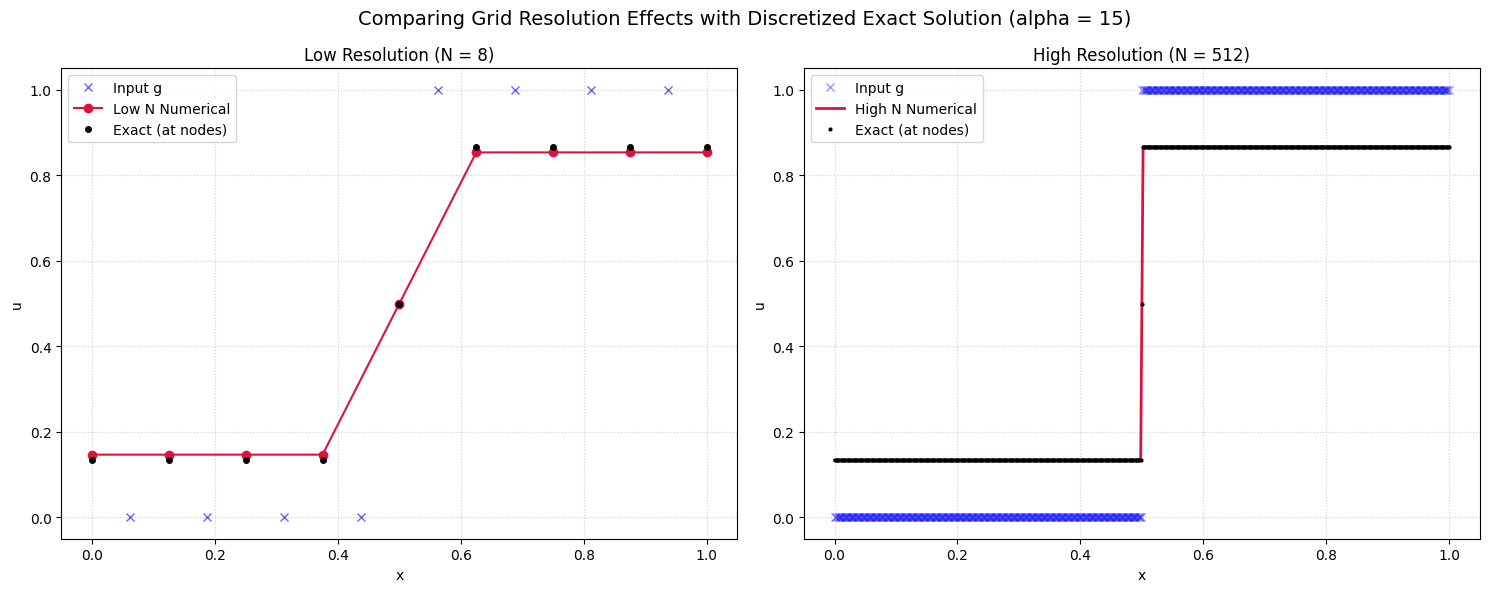

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Define the two grid resolutions
N_low = 8
N_high = 512
alpha = 15

# Run solver with low N
T_low = 0.9 * np.sqrt(1 / N_low)
u_low, _, _, _, g_low = Solve(N_low, alpha, T_low, s=1, max_its=2000)

# Run solver with high N
T_high = 0.9 * np.sqrt(1 / N_high)
u_high, _, _, _, g_high = Solve(N_high, alpha, T_high, s=1, max_its=2000)

# Set up spatial coordinates for plotting
X_low = np.linspace(0, 1, N_low + 1)
Y_low = np.linspace(0, 1, N_low, endpoint=False) + (1 / (2 * N_low))

X_high = np.linspace(0, 1, N_high + 1)
Y_high = np.linspace(0, 1, N_high, endpoint=False) + (1 / (2 * N_high))

# Compute exact analytical solution discretized at the nodes
exact_low = np.heaviside(X_low - 0.5, 0.5) - (2 / alpha) * np.sign(X_low - 0.5)
exact_high = np.heaviside(X_high - 0.5, 0.5) - (2 / alpha) * np.sign(X_high - 0.5)

plt.figure(figsize=(15, 6))

# Left subplot: Low N
plt.subplot(1, 2, 1)
plt.plot(Y_low, g_low, 'x', color='blue', alpha=0.6, label='Input g')
plt.plot(X_low, u_low, 'o-', color='crimson', label='Low N Numerical')
plt.plot(X_low, exact_low, 'k.', label='Exact (at nodes)', markersize=8)
plt.title(f'Low Resolution (N = {N_low})')
plt.xlabel('x')
plt.ylabel('u')
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend()

# Right subplot: High N
plt.subplot(1, 2, 2)
plt.plot(Y_high, g_high, 'x', color='blue', alpha=0.4, label='Input g')
plt.plot(X_high, u_high, '-', color='crimson', lw=2, label='High N Numerical')
plt.plot(X_high, exact_high, 'k.', label='Exact (at nodes)', markersize=4)
plt.title(f'High Resolution (N = {N_high})')
plt.xlabel('x')
plt.ylabel('u')
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend()

plt.suptitle(f'Comparing Grid Resolution Effects with Discretized Exact Solution (alpha = {alpha})', fontsize=14)
plt.tight_layout()
plt.show()

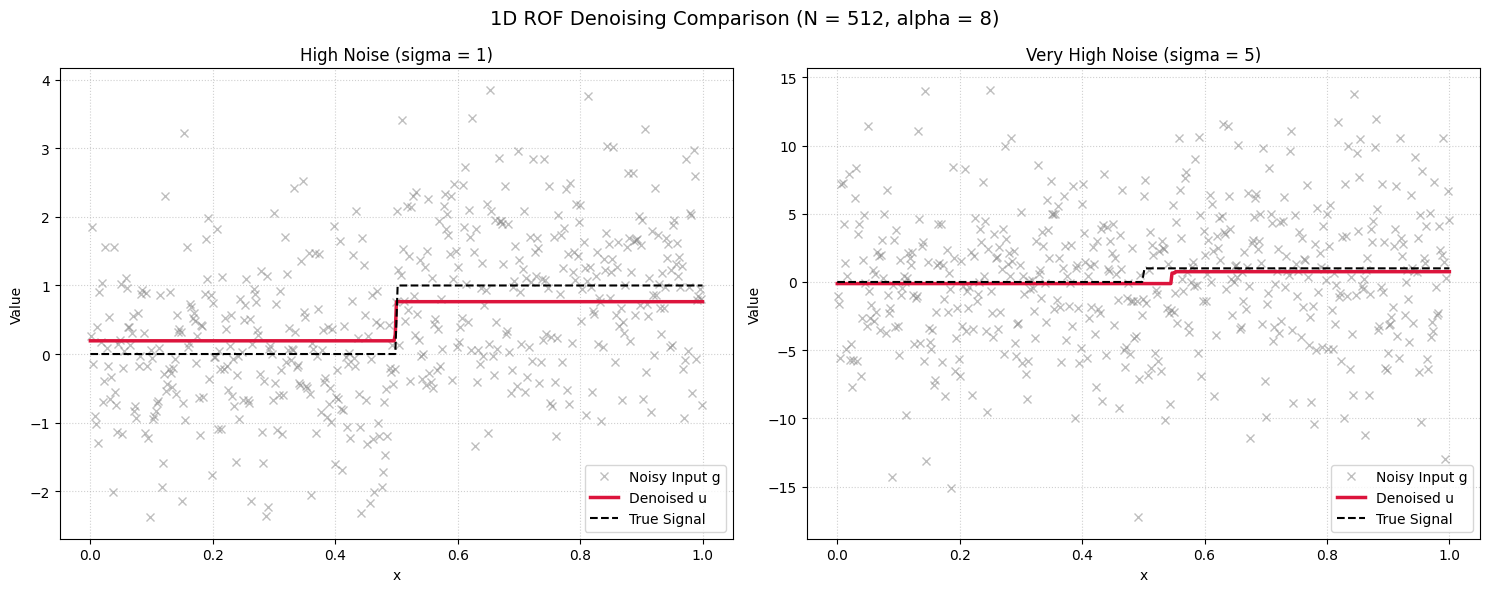

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

N = 256*2
alpha = 8
T = 0.9 * np.sqrt(1 / N)

# Run solver with low noise
sigma_low = 1
u_low, _, _, _, g_low = Solve(N, alpha, T, noise=sigma_low, s=1, max_its=10000)

# Run solver with high noise
sigma_high = 5
u_high, _, _, _, g_high = Solve(N, alpha, T, noise=sigma_high, s=1, max_its=10000)

X = np.linspace(0, 1, N + 1)
Y = np.linspace(0, 1, N, endpoint=False) + (1 / (2 * N))
true_signal = np.heaviside(X - 1/2, 1/2)

plt.figure(figsize=(15, 6))

# Left subplot: Low Noise
plt.subplot(1, 2, 1)
plt.plot(Y, g_low, 'x', color='gray', alpha=0.5, label='Noisy Input g')
plt.plot(X, u_low, '-', color='crimson', lw=2.5, label='Denoised u')
plt.plot(X, true_signal, 'k--', label='True Signal')
plt.title(f'High Noise (sigma = {sigma_low})')
plt.xlabel('x')
plt.ylabel('Value')
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend()

# Right subplot: High Noise
plt.subplot(1, 2, 2)
plt.plot(Y, g_high, 'x', color='gray', alpha=0.5, label='Noisy Input g')
plt.plot(X, u_high, '-', color='crimson', lw=2.5, label='Denoised u')
plt.plot(X, true_signal, 'k--', label='True Signal')
plt.title(f'Very High Noise (sigma = {sigma_high})')
plt.xlabel('x')
plt.ylabel('Value')
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend()

plt.suptitle(f'1D ROF Denoising Comparison (N = {N}, alpha = {alpha})', fontsize=14)
plt.tight_layout()
plt.show()

We now see what happens when we add Gaussian noise with standard deviation $\sigma$ and mean $0$ to $g$. Let's see how our model works to filter this noise.

Final Residual 0.0000069547
Iterations Requires 2000


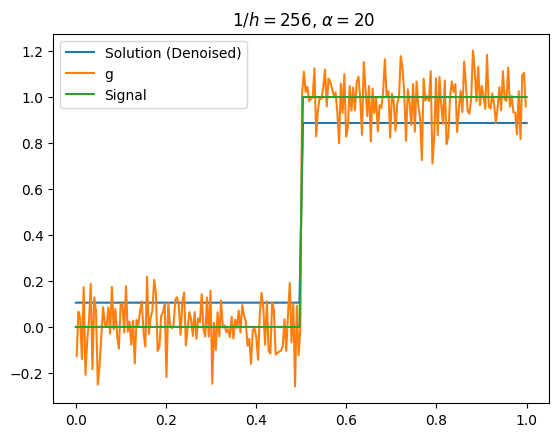

In [ ]:
N = 256
alpha = 20
sigma = .1
T = .9*np.sqrt((1/N))
###################
u, p, residuals, num_iter, g = Solve(N,alpha,T, noise = sigma, s=1)
print(f"Final Residual {residuals[-1]:.10f}")
print(f"Iterations Requires {num_iter}")
X = np.linspace(0,1,N+1)
Y = np.linspace(0,1, N, endpoint = False) + (1/(2*N))
plt.plot(X,u, label= "Solution (Denoised)")
plt.plot(Y,g, label = "g")

if alpha <= 4:
  signal = np.ones(N+1) * 1/2
else:
  signal = np.heaviside(X - 1/2, 1/2)

plt.plot(X, signal, label = "Signal")
plt.legend()
plt.title(rf" $1/h = {N}$, $\alpha = {alpha}$")
plt.show()


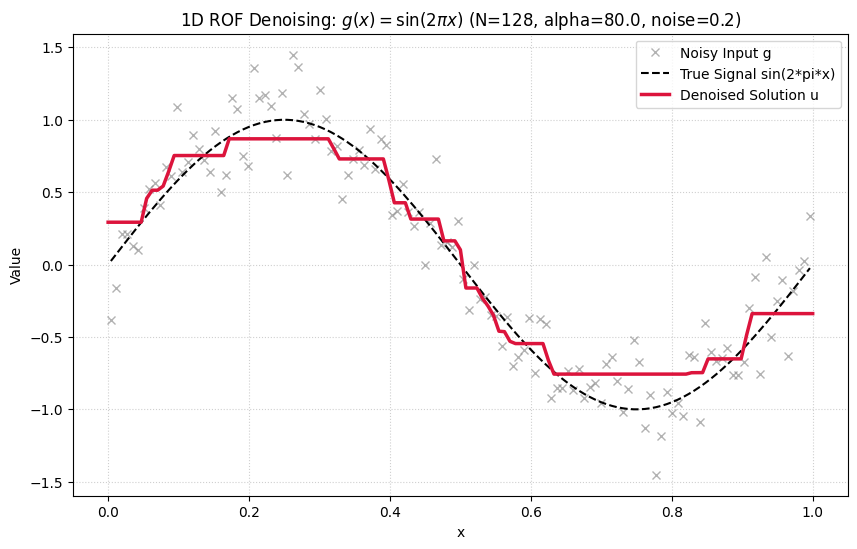

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import torch

# 1. Define custom get_g for sin(2*pi*x) with optional noise
def get_g_sin(N, noise=0.0):
    x = np.linspace(0, 1, N, endpoint=False) + (1.0 / (2 * N))
    return np.sin(2 * np.pi * x) + np.random.normal(0, noise, N)

# Overwrite the temporary function to inject g_sin into our solver
original_get_g = get_g
get_g = lambda N, noise=0.0: get_g_sin(N, noise)

# 2. Setup simulation parameters
N = 128
alpha = 80.0
sigma = 0.2
T = 0.9 * np.sqrt(1.0 / N)

# 3. Solve
u, p, residuals, num_iter, g_noisy = Solve(N, alpha, T, noise=sigma, s=1, max_its=1500)

# 4. Restore original generator
get_g = original_get_g

# 5. Plot Results
X_nodes = np.linspace(0, 1, N + 1)
Y_cells = np.linspace(0, 1, N, endpoint=False) + (1.0 / (2 * N))

plt.figure(figsize=(10, 6))
plt.plot(Y_cells, g_noisy, 'x', color='gray', alpha=0.6, label='Noisy Input g')
plt.plot(Y_cells, np.sin(2 * np.pi * Y_cells), 'k--', label='True Signal sin(2*pi*x)', lw=1.5)
plt.plot(X_nodes, u, '-', color='crimson', label='Denoised Solution u', lw=2.5)
plt.title(f"1D ROF Denoising: $g(x) = \\sin(2\\pi x)$ (N={N}, alpha={alpha}, noise={sigma})")
plt.xlabel("x")
plt.ylabel("Value")
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend()
plt.show()

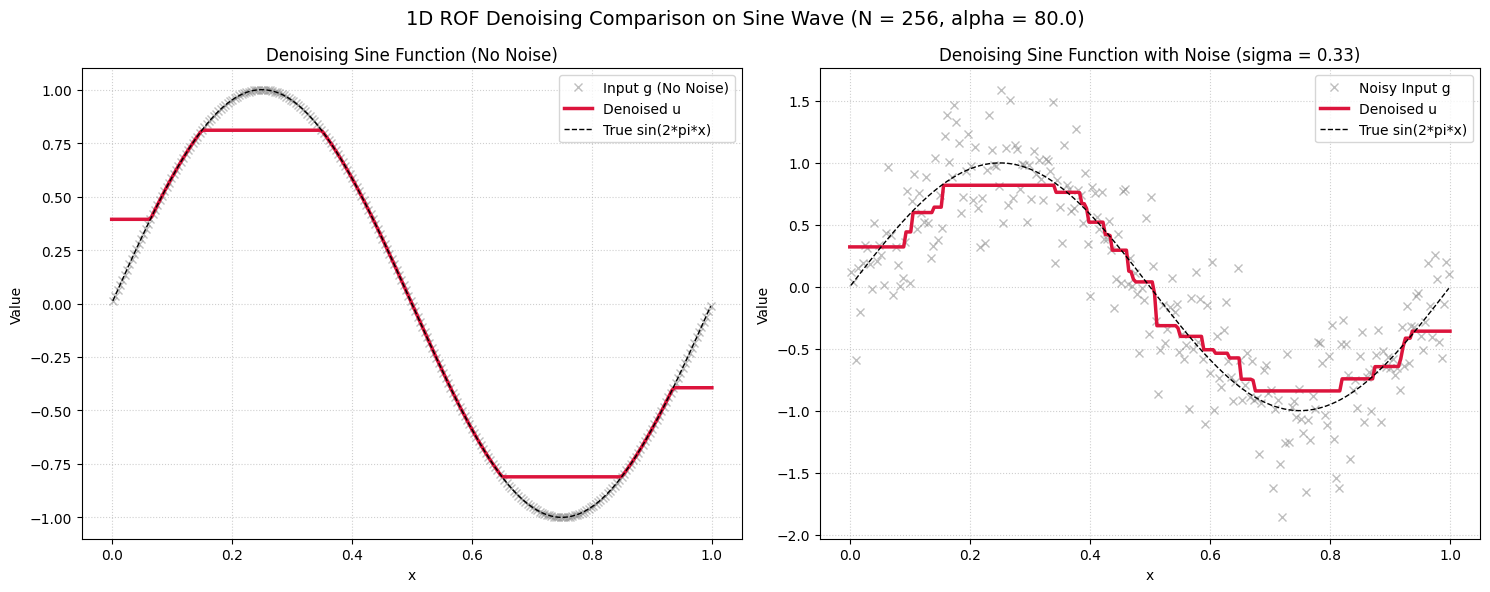

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Define custom generator for a sine function
def get_g_sin(N, noise=0.0):
    x = np.linspace(0, 1, N, endpoint=False) + (1.0 / (2 * N))
    return np.sin(2 * np.pi * x) + np.random.normal(0, noise, N)

# Save original generator and swap in the sine generator
original_get_g = get_g
get_g = lambda N, noise=0.0: get_g_sin(N, noise)

# 2. Setup parameters
N = 256
alpha = 80.0
T = 0.9 * np.sqrt(1.0 / N)

# Solve for no-noise case
u_clean, _, _, _, g_clean = Solve(N, alpha, T, noise=0.0, s=1, max_its=2000)

# Solve for noisy case
sigma = 0.33
u_noisy, _, _, _, g_noisy = Solve(N, alpha, T, noise=sigma, s=1, max_its=2000)

# Restore original generator
get_g = original_get_g

# 3. Setup plotting coordinates
X_nodes = np.linspace(0, 1, N + 1)
Y_cells = np.linspace(0, 1, N, endpoint=False) + (1.0 / (2 * N))

plt.figure(figsize=(15, 6))

# Left Plot: No Noise
plt.subplot(1, 2, 1)
plt.plot(Y_cells, g_clean, 'x', color='gray', alpha=0.5, label='Input g (No Noise)')
plt.plot(X_nodes, u_clean, '-', color='crimson', lw=2.5, label='Denoised u')
plt.plot(Y_cells, np.sin(2 * np.pi * Y_cells), 'k--', lw=1, label='True sin(2*pi*x)')
plt.title('Denoising Sine Function (No Noise)')
plt.xlabel('x')
plt.ylabel('Value')
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend()

# Right Plot: With Noise
plt.subplot(1, 2, 2)
plt.plot(Y_cells, g_noisy, 'x', color='gray', alpha=0.5, label='Noisy Input g')
plt.plot(X_nodes, u_noisy, '-', color='crimson', lw=2.5, label='Denoised u')
plt.plot(Y_cells, np.sin(2 * np.pi * Y_cells), 'k--', lw=1, label='True sin(2*pi*x)')
plt.title(f'Denoising Sine Function with Noise (sigma = {sigma})')
plt.xlabel('x')
plt.ylabel('Value')
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend()

plt.suptitle(f'1D ROF Denoising Comparison on Sine Wave (N = {N}, alpha = {alpha})', fontsize=14)
plt.tight_layout()
plt.show()

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import torch

# --- Redefining the 1D solver functions ---
def get_g(N, noise=0):
    temp = np.linspace(0, 1, N) - 1/2
    return np.heaviside(temp, 1) + np.random.normal(0, noise, N)

def IP(X, Y, s=-1):
    device = X.device
    N = len(X) - 1
    h = 1.0 / N
    X_i = X[:-1]
    X_next = X[1:]
    Y_i = Y[:-1]
    Y_next = Y[1:]
    dX = X_next - X_i
    dY = Y_next - Y_i
    L2 = torch.sum(h * X_i * Y_i + (h**2 / 2) * dX * Y_i + (h**2 / 2) * dY * X_i + (h**3 / 3) * dX * dY)
    if s != -1:
        H1 = torch.sum(dX * dY) * (h**(s-1))
    else:
        H1 = 0.0
    return L2 + H1

def grad(X):
    return (X[1:] - X[:-1]) * (len(X) - 1)

def get_A(N, s=-1, device='cpu'):
    phi_1 = torch.zeros(N+1, dtype=torch.float64, device=device)
    phi_2 = torch.zeros(N+1, dtype=torch.float64, device=device)
    phi_1[1] = 1
    phi_2[2] = 1
    a = IP(phi_1, phi_1, s).item()
    b = IP(phi_1, phi_2, s).item()
    A = torch.zeros((N+1, N+1), dtype=torch.float64, device=device)
    A.fill_diagonal_(b)
    A.diagonal().fill_(a)
    A[0, 0] = a / 2
    A[-1, -1] = a / 2
    for i in range(N):
        A[i+1, i] = b
        A[i, i+1] = b
    return A

def get_K(N, device='cpu'):
    K = torch.zeros((N+1, N), dtype=torch.float64, device=device)
    K.diagonal().fill_(-1.0)
    for i in range(N):
        K[i+1, i] = 1.0
    return K

def get_C(N, device='cpu'):
    C = torch.zeros((N+1, N), dtype=torch.float64, device=device)
    C.diagonal().fill_(1.0 / (2 * N))
    for i in range(N):
        C[i+1, i] = 1.0 / (2 * N)
    return C

def Mat_Solver(uk, duk, pk, T, alpha, g, A, B, C, K, s=-1):
    device = uk.device
    N = len(pk)
    u_tilde = uk + T * duk
    p_next = (pk + T * grad(u_tilde))
    p_next = p_next / torch.maximum(torch.ones_like(p_next), torch.abs(p_next))
    S1 = torch.mv(-K, p_next)
    S2 = torch.mv(-alpha * B, uk)
    S3 = torch.mv(alpha * C, g)
    rhs = S1 + S2 + S3
    lhs_matrix = A + alpha * T * B
    du_next = torch.linalg.solve(lhs_matrix, rhs)
    u_next = uk + du_next * T
    return p_next, du_next, u_next

def Solve(N, alpha, T, noise=0, s=1, eps_stop=1e-8, max_its=2000):
    device = torch.device()

## Let's run a convergence study for residuals:

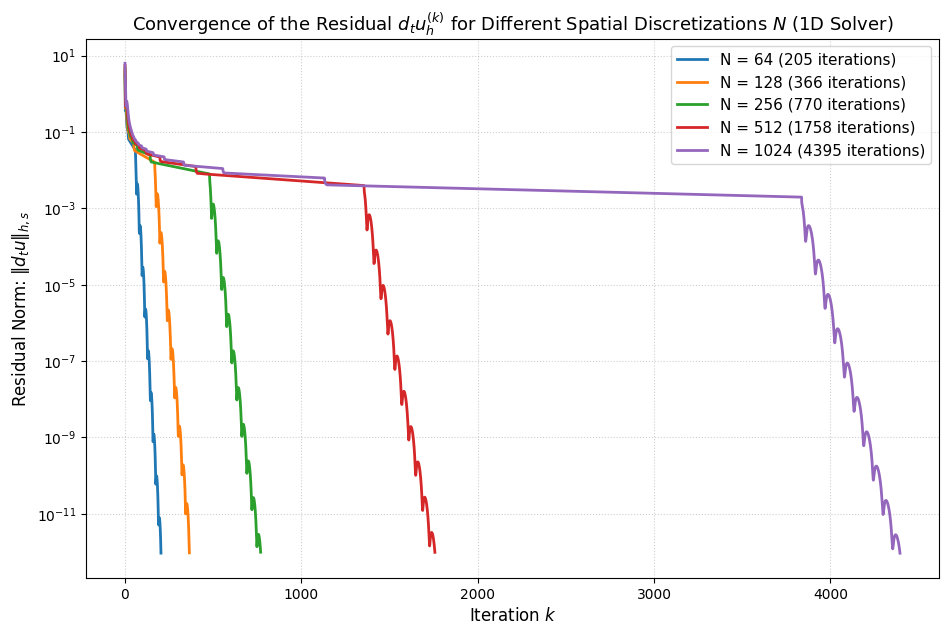

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import torch


N_values = [64, 128, 256, 512, 1024]
alpha = 20
max_its = 5000
eps_stop = 1e-12

plt.figure(figsize=(11, 7))

# Loop over the different resolutions to collect and plot residuals
for N in N_values:
    # Time step adapted to the spatial discretization
    T = 0.9 * np.sqrt(1 / N)

    # Solve
    _, _, residuals, num_iter, _ = Solve(N, alpha, T, s=1, eps_stop=eps_stop, max_its=max_its)

    # Semi-logarithmic plot of the residual norm
    plt.semilogy(range(1, len(residuals) + 1), residuals,
                 lw=2, label=f'N = {N} ({num_iter} iterations)')

plt.xlabel('Iteration $k$', fontsize=12)
plt.ylabel(r'Residual Norm: $\|d_t u\|_{h,s}$', fontsize=12)
plt.title('Convergence of the Residual $d_t u_{h}^{(k)}$ for Different Spatial Discretizations $N$ (1D Solver)', fontsize=13)
plt.grid(True, which="both", linestyle=':', alpha=0.6)
plt.legend(fontsize=11)
plt.show()

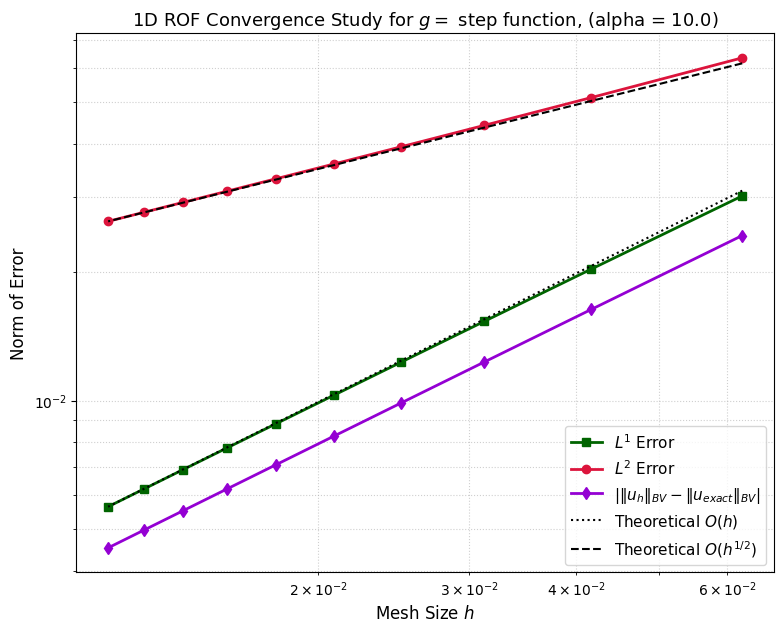

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import torch

alpha = 10.0 # alpha > 4 assumed

N_vals = [16 + 8 * i for i in range(10)]
l2_errors = []
l1_errors = []
bv_diffs = []
h_vals = []

# True BV norm is 1 - 4/alpha when alpha > 4
true_bv = 1.0 - 4.0 / alpha

for N in N_vals:
    h = 1.0 / N
    h_vals.append(h)
    Y = np.linspace(0, 1, N, endpoint=False) + (1 / (2 * N))
    exact = np.heaviside(Y - 1/2, 1/2) - (2 / alpha) * np.sign(Y - 1/2)
    T = np.sqrt(1 / N) * 0.8
    u_num, p, residuals, num_iter, g_noisy = Solve(N, alpha, T, noise=0.0, s=1, max_its=5000, eps_stop=1e-12)

    l2_err_sq_total = 0.0
    l1_err_total = 0.0

    # u_num is defined on the N+1 nodes; exact is defined on the N cell averages
    for i in range(N):
        u_left = u_num[i]
        u_right = u_num[i+1]
        C = exact[i]

        e_left = u_left - C
        e_right = u_right - C

        # 1. Exact continuous L^2 norm integral of linear function e(x) on cell of size h:
        l2_err_sq_total += (h / 3.0) * (e_left**2 + e_left * e_right + e_right**2)

        # 2. Exact continuous L^1 norm integral of linear function e(x) on cell of size h:
        if e_left * e_right >= 0.0:
            l1_err_total += h * (np.abs(e_left) + np.abs(e_right)) / 2.0
        else:
            # The error changes sign inside the interval; split the integral at the zero-crossing
            abs_left = np.abs(e_left)
            abs_right = np.abs(e_right)
            l1_err_total += 0.5 * h * (e_left**2 + e_right**2) / (abs_left + abs_right + 1e-15)

    l2_errors.append(np.sqrt(l2_err_sq_total))
    l1_errors.append(l1_err_total)

    # Discrete BV norm of u in 1D is defined as sum_{i=0}^{N-1} |u_{i+1} - u_i|
    numerical_bv = np.sum(np.abs(np.diff(u_num)))
    bv_diffs.append(np.abs(numerical_bv - true_bv))

plt.figure(figsize=(9, 7))
plt.loglog(h_vals, l1_errors, 's-', color='darkgreen', lw=2, label=r'$L^1$ Error')
plt.loglog(h_vals, l2_errors, 'o-', color='crimson', lw=2, label=r'$L^2$ Error')
plt.loglog(h_vals, bv_diffs, 'd-', color='darkviolet', lw=2, label=r'$| ‖u_h‖_{BV} - ‖u_{exact}‖_{BV} |$')

# Reference fit lines
# O(h) reference line for L1 error
ref_h = np.array([h_vals[0], h_vals[-1]])
ref_l1 = l1_errors[-1] * (ref_h / ref_h[-1])
plt.loglog(ref_h, ref_l1, 'k:', lw=1.5, label=r'Theoretical $O(h)$')

# O(h^{1/2}) reference line for L2 error
ref_l2 = l2_errors[-1] * np.sqrt(ref_h / ref_h[-1])
plt.loglog(ref_h, ref_l2, 'k--', lw=1.5, label=r'Theoretical $O(h^{1/2})$')

plt.xlabel(r'Mesh Size $h$', fontsize=12)
plt.ylabel(r'Norm of Error', fontsize=12)
plt.title(fr'1D ROF Convergence Study for $g = $ step function, (alpha = {alpha})', fontsize=13)
plt.grid(True, which="both", ls=":", alpha=0.6)
plt.legend(fontsize=11)
plt.show()

```markdown
## Two-Dimensional Solver using Finite Elements

We now generalize our primal-dual solver to the 2D domain $(0,1)^2$ using triangular P^1 Lagrange elements.

* $u_{h}$ is continuous and peicewise linear, and is stored as a vector of nodal values as before.

* The dual variable $\vec{p}$ is discontinuous and constant on each triangle, and stored as a tensor of cell values.  

* Let's write a module to generate a structured triangular mesh

* The basic idea is to decompose $\Omega$ into $1/N_{x} \times 1/N_{y}$ rectangles, and then each rectangle is broken into two triangles.

```

In [ ]:
import numpy as np
import scipy.sparse as sp
import scipy.sparse.linalg
import matplotlib.pyplot as plt

def generate_mesh_2d(Nx, Ny):
    """
    Generates a structured triangular mesh for [0, 1] x [0, 1]
    We break the domain into rectanges, and make two triangles per rectangle
    """
    x = np.linspace(0, 1, Nx + 1)
    y = np.linspace(0, 1, Ny + 1)
    X, Y = np.meshgrid(x, y)
    nodes = np.vstack([X.ravel(), Y.ravel()]).T

    elements = []
    for j in range(Ny):
        for i in range(Nx):
            n0 = j * (Nx + 1) + i
            n1 = n0 + 1
            n2 = (j + 1) * (Nx + 1) + i
            n3 = n2 + 1
            # Triangle 1
            elements.append([n0, n1, n2])
            # Triangle 2
            elements.append([n1, n3, n2])

    return nodes, np.array(elements)

nodes, elements = generate_mesh_2d(4, 4)
print(f"Generated structured grid with {len(nodes)} nodes and {len(elements)} triangles.")

Generated structured grid with 25 nodes and 32 triangles.


Let's plot an example mesh to show the geometry we have contructed:

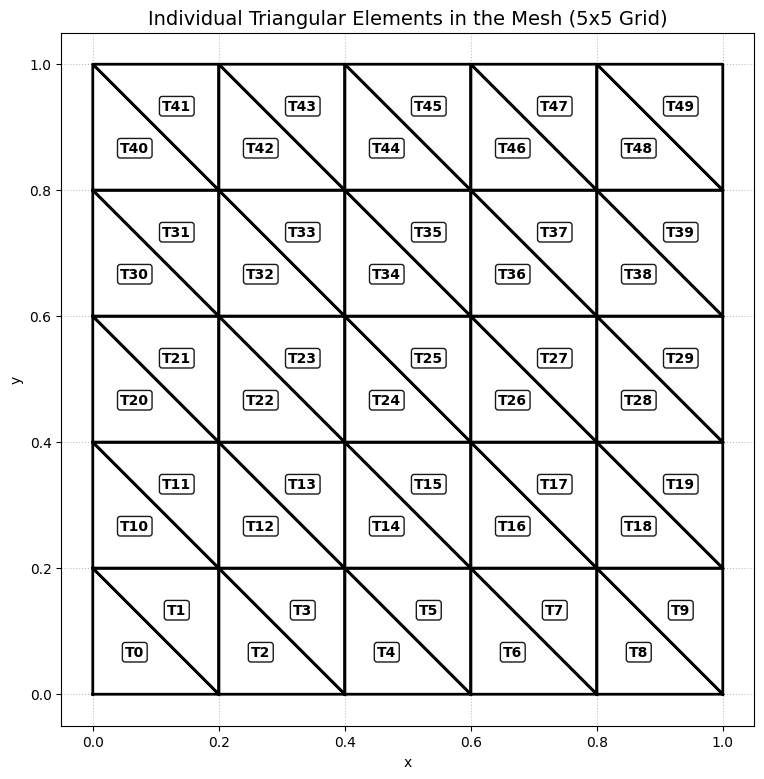

In [ ]:
import matplotlib.pyplot as plt
import numpy as np


mesh_Nx, mesh_Ny = 5, 5
vis_nodes, vis_elements = generate_mesh_2d(mesh_Nx, mesh_Ny)

plt.figure(figsize=(9, 9))

for idx, elem in enumerate(vis_elements):

    triangle_coords = vis_nodes[elem]
    polygon_coords = np.vstack([triangle_coords, triangle_coords[0]])


    plt.fill(polygon_coords[:, 0], polygon_coords[:, 1], facecolor='white', zorder=1)
    plt.plot(polygon_coords[:, 0], polygon_coords[:, 1], 'k-', lw=2, zorder=2)


    centroid_x = np.mean(triangle_coords[:, 0])
    centroid_y = np.mean(triangle_coords[:, 1])
    plt.text(centroid_x, centroid_y, f"T{idx}", fontsize=10, ha='center', va='center',
             fontweight='bold', color='black', zorder=3,
             bbox=dict(boxstyle='round,pad=0.2', fc='white', alpha=0.9, ec='black', lw=1))

plt.title(f"Individual Triangular Elements in the Mesh ({mesh_Nx}x{mesh_Ny} Grid)", fontsize=14)
plt.xlabel("x")
plt.ylabel("y")
plt.xlim(-0.05, 1.05)
plt.ylim(-0.05, 1.05)
plt.gca().set_aspect('equal')
plt.grid(True, linestyle=':', color='gray', alpha=0.5)
plt.show()

We now compute the mass matrix $M = (\phi_{i}, \phi_{j})$.

In [ ]:
import numpy as np
import torch

def compute_mass_matrix_2d(nodes, elements, device='cpu'):
    """
    Computes the global L2 mass matrix for a 2D triangular mesh with P1 elements.
    Returns a PyTorch sparse coo tensor directly on the target device.
    """
    num_nodes = len(nodes)
    nodes_t = torch.tensor(nodes, dtype=torch.float64, device=device)
    elem_t = torch.tensor(elements, dtype=torch.long, device=device)

    coords = nodes_t[elem_t]
    v1 = coords[:, 1] - coords[:, 0]
    v2 = coords[:, 2] - coords[:, 0]
    areas = 0.5 * torch.abs(v1[:, 0] * v2[:, 1] - v1[:, 1] * v2[:, 0])

    m_loc_template = torch.tensor([
        [2.0, 1.0, 1.0],
        [1.0, 2.0, 1.0],
        [1.0, 1.0, 2.0]
    ], dtype=torch.float64, device=device) / 12.0

    m_locs = areas.unsqueeze(1).unsqueeze(2) * m_loc_template.unsqueeze(0)

    rows = elem_t.unsqueeze(2).expand(-1, -1, 3).flatten()
    cols = elem_t.unsqueeze(1).expand(-1, 3, -1).flatten()
    vals = m_locs.flatten()

    indices = torch.stack([rows, cols])
    M_t = torch.sparse_coo_tensor(indices, vals, size=(num_nodes, num_nodes), device=device).coalesce()
    return M_t

We now build the stiffness matrix $S = (\nabla \phi_{i}, \nabla \phi_{j})$.

In [ ]:
import numpy as np
import torch

def compute_stiffness_matrix_2d(nodes, elements, device='cpu'):
    """
    Computes the global H1 semi-norm stiffness matrix for a 2D triangular mesh with P1 elements.
    Returns a PyTorch sparse coo tensor directly on the target device.
    """
    num_nodes = len(nodes)
    nodes_t = torch.tensor(nodes, dtype=torch.float64, device=device)
    elem_t = torch.tensor(elements, dtype=torch.long, device=device)

    coords = nodes_t[elem_t]
    v1 = coords[:, 1] - coords[:, 0]
    v2 = coords[:, 2] - coords[:, 0]
    areas = 0.5 * torch.abs(v1[:, 0] * v2[:, 1] - v1[:, 1] * v2[:, 0])

    b = torch.stack([
        coords[:, 1, 1] - coords[:, 2, 1],
        coords[:, 2, 1] - coords[:, 0, 1],
        coords[:, 0, 1] - coords[:, 1, 1]
    ], dim=1) / (2.0 * areas.unsqueeze(1))

    c = torch.stack([
        coords[:, 2, 0] - coords[:, 1, 0],
        coords[:, 0, 0] - coords[:, 2, 0],
        coords[:, 1, 0] - coords[:, 0, 0]
    ], dim=1) / (2.0 * areas.unsqueeze(1))

    s_locs = areas.unsqueeze(1).unsqueeze(2) * (
        torch.bmm(b.unsqueeze(2), b.unsqueeze(1)) + torch.bmm(c.unsqueeze(2), c.unsqueeze(1))
    )

    rows = elem_t.unsqueeze(2).expand(-1, -1, 3).flatten()
    cols = elem_t.unsqueeze(1).expand(-1, 3, -1).flatten()
    vals = s_locs.flatten()

    indices = torch.stack([rows, cols])
    S_t = torch.sparse_coo_tensor(indices, vals, size=(num_nodes, num_nodes), device=device).coalesce()
    return S_t

We now build a function giving $g \in P^{0}$ with a gaussian noise parameter.

In [ ]:
def get_g_2d(nodes, elements, noise_level=0.0):
    """
    Computes the exact cell averages of the characteristic function of the square
    centered at (1/2, 1/2) with side lengths 1/4 for each triangle in the 2D grid.
    Returns a vector of length equal to the number of elements (triangles).

    Parameters:
    nodes : ndarray of shape (num_nodes, 2)
    elements : ndarray of shape (num_elements, 3)
    noise_level : float, standard deviation of Gaussian noise to add
    """
    num_elements = len(elements)
    g_face = np.zeros(num_elements)

    # Square centered at (0.5, 0.5) with side length 0.25
    # Bounds are: [0.5 - 0.125, 0.5 + 0.125] = [0.375, 0.625]
    for e_idx, elem in enumerate(elements):
        centroid = np.mean(nodes[elem], axis=0)
        if (0.375 <= centroid[0] <= 0.625) and (0.375 <= centroid[1] <= 0.625):
            g_face[e_idx] = 1.0

    if noise_level > 0.0:
        g_face += np.random.normal(0, noise_level, num_elements)

    return g_face

# Test call on the mesh
g_test = get_g_2d(nodes, elements, noise_level=0.0)
print(f"Signal g initialized with {np.sum(g_test > 0)} triangles inside the square out of {len(g_test)} total triangles.")

Signal g initialized with 2 triangles inside the square out of 32 total triangles.


### 2D $g$ visualized:



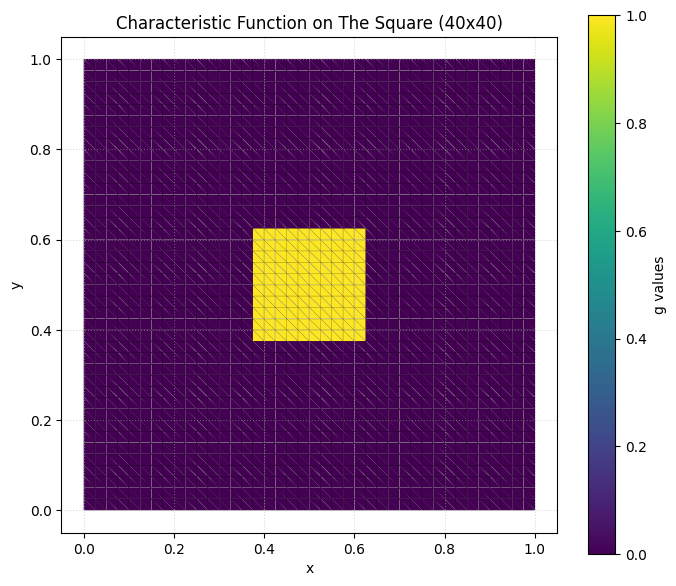

In [ ]:
import matplotlib.pyplot as plt

Nx_plot, Ny_plot = 40, 40
nodes_plot, elements_plot = generate_mesh_2d(Nx_plot, Ny_plot)
g_plot = get_g_2d(nodes_plot, elements_plot, noise_level=0.0)

plt.figure(figsize=(8, 7))
tripcolor_plot = plt.tripcolor(nodes_plot[:, 0], nodes_plot[:, 1], elements_plot, facecolors=g_plot, edgecolors='k', lw=0.1, cmap='viridis')
plt.colorbar(tripcolor_plot, label='g values')
plt.title(f"Characteristic Function on The Square ({Nx_plot}x{Ny_plot})")
plt.xlabel("x")
plt.ylabel("y")
plt.gca().set_aspect('equal')
plt.grid(True, linestyle=':', alpha=0.5)
plt.show()

### 2D Primal-Dual ROF Solver Implementation

Here we construct the necessary operators:
1. The discrete gradient $\nabla$ which maps nodal values ($P^1$) to element-wise constant values ($P^0$) on each triangular element.
2. The divergence operator $div: P^{0} \to P^{1}$ (the adjoint of the gradient).
3. The projection $P: P^{1} \to P^{0}$ which associates the average nodal value of its three vertices with each element.
4. The Chambolle-Pock iteration loop (primal-dual).

In [ ]:
import numpy as np
import torch

def get_grad_2d(nodes, elements, device='cpu'):
    """
    Assembles the discrete gradient operator mapping P1 nodal values to P0 cell values.
    Returns two PyTorch sparse coo tensors (grad_x, grad_y) directly on the target device.
    """
    num_nodes = len(nodes)
    num_elements = len(elements)

    nodes_t = torch.tensor(nodes, dtype=torch.float64, device=device)
    elem_t = torch.tensor(elements, dtype=torch.long, device=device)

    coords = nodes_t[elem_t]
    v1 = coords[:, 1] - coords[:, 0]
    v2 = coords[:, 2] - coords[:, 0]
    areas = 0.5 * torch.abs(v1[:, 0] * v2[:, 1] - v1[:, 1] * v2[:, 0])

    b = torch.stack([
        coords[:, 1, 1] - coords[:, 2, 1],
        coords[:, 2, 1] - coords[:, 0, 1],
        coords[:, 0, 1] - coords[:, 1, 1]
    ], dim=1) / (2.0 * areas.unsqueeze(1))

    c = torch.stack([
        coords[:, 2, 0] - coords[:, 1, 0],
        coords[:, 0, 0] - coords[:, 2, 0],
        coords[:, 1, 0] - coords[:, 0, 0]
    ], dim=1) / (2.0 * areas.unsqueeze(1))

    rows = torch.arange(num_elements, dtype=torch.long, device=device).unsqueeze(1).expand(-1, 3).flatten()
    cols = elem_t.flatten()

    indices = torch.stack([rows, cols])
    grad_x_t = torch.sparse_coo_tensor(indices, b.flatten(), size=(num_elements, num_nodes), device=device).coalesce()
    grad_y_t = torch.sparse_coo_tensor(indices, c.flatten(), size=(num_elements, num_nodes), device=device).coalesce()

    return grad_x_t, grad_y_t

### 2D solver:
We build the solver, which is the same as before, just more complicated due to the more difficult geometry

In [ ]:
import torch
import numpy as np

def Solve_2D_ROF(nodes, elements, alpha, T, noise_level=0.0, eps_stop=1e-5, max_its=3000):
    """
    Fully optimized 2D ROF Solver utilizing PyTorch native sparse structures directly on device.
    """
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    num_nodes = len(nodes)
    num_elements = len(elements)
    Nx = int(np.sqrt(num_nodes)) - 1
    h = 1.0 / Nx

    # Generate mesh metadata on GPU directly
    nodes_t = torch.tensor(nodes, dtype=torch.float64, device=device)
    elem_t = torch.tensor(elements, dtype=torch.long, device=device)

    # Compute element areas
    coords = nodes_t[elem_t]
    v1 = coords[:, 1] - coords[:, 0]
    v2 = coords[:, 2] - coords[:, 0]
    areas_t = 0.5 * torch.abs(v1[:, 0] * v2[:, 1] - v1[:, 1] * v2[:, 0])

    # Direct GPU matrix construction (Zero CPU-to-GPU overhead)
    M = compute_mass_matrix_2d(nodes, elements, device=device)
    S = compute_stiffness_matrix_2d(nodes, elements, device=device)
    grad_x, grad_y = get_grad_2d(nodes, elements, device=device)

    # Initialize g directly on device
    g_cpu = get_g_2d(nodes, elements, noise_level=noise_level)
    g = torch.tensor(g_cpu, dtype=torch.float64, device=device)

    # Vectorized source projection
    C_g = torch.zeros(num_nodes, dtype=torch.float64, device=device)
    C_g.index_add_(0, elem_t.flatten(), (g * areas_t / 3.0).repeat_interleave(3))

    # Variable initialization
    g_mean = torch.sum(g * areas_t) / torch.sum(areas_t)
    u = torch.full((num_nodes,), g_mean, dtype=torch.float64, device=device)
    du = torch.zeros(num_nodes, dtype=torch.float64, device=device)
    px = torch.zeros(num_elements, dtype=torch.float64, device=device)
    py = torch.zeros(num_elements, dtype=torch.float64, device=device)

    A = (M + S * h).coalesce()
    lhs_matrix = (A + M * (alpha * T)).coalesce()

    # Optimized CG with inline execution and pre-allocated structures
    def cg_solver(A_sparse, b, x0, rtol=1e-12, max_iter=250):
        x = x0.clone()
        r = b - torch.mv(A_sparse, x)
        p = r.clone()
        r_dot_old = torch.dot(r, r)

        for _ in range(max_iter):
            Ap = torch.mv(A_sparse, p)
            denom = torch.dot(p, Ap)
            if denom == 0:
                break
            alpha_cg = r_dot_old / denom
            x.add_(p, alpha=alpha_cg.item())
            r.add_(Ap, alpha=-alpha_cg.item())
            r_dot_new = torch.dot(r, r)
            if torch.sqrt(r_dot_new) < rtol:
                break
            p.mul_(r_dot_new / r_dot_old).add_(r)
            r_dot_old = r_dot_new
        return x

    residuals = []
    for iteration in range(max_its):
        u_tilde = u + du * T

        ux = torch.mv(grad_x, u_tilde)
        uy = torch.mv(grad_y, u_tilde)

        px_temp = px + T * ux
        py_temp = py + T * uy

        p_norm = torch.maximum(torch.ones_like(px_temp), torch.sqrt(px_temp**2 + py_temp**2))
        px = px_temp / p_norm
        py = py_temp / p_norm

        div_p = -(torch.mv(torch.transpose(grad_x, 0, 1), areas_t * px) +
                  torch.mv(torch.transpose(grad_y, 0, 1), areas_t * py))

        rhs = div_p - alpha * torch.mv(M, u) + alpha * C_g
        du = cg_solver(lhs_matrix, rhs, du, rtol=1e-12)
        u.add_(du, alpha=T)

        res = torch.sqrt(torch.dot(du, torch.mv(A, du))).item()
        residuals.append(res)

        if res < eps_stop:
            break

    return u.cpu().numpy(), px.cpu().numpy(), py.cpu().numpy(), residuals, g_cpu

We now plot the numerical solution when $g$ is the characteristic function on the square:

/tmp/ipykernel_18940/1980920750.py:31: UserWarning: Sparse invariant checks are implicitly disabled. Memory errors (e.g. SEGFAULT) will occur when operating on a sparse tensor which violates the invariants, but checks incur performance overhead. To silence this warning, explicitly opt in or out. See `torch.sparse.check_sparse_tensor_invariants.__doc__` for guidance.  (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/Context.cpp:848.)
  M_t = torch.sparse_coo_tensor(indices, vals, size=(num_nodes, num_nodes), device=device).coalesce()


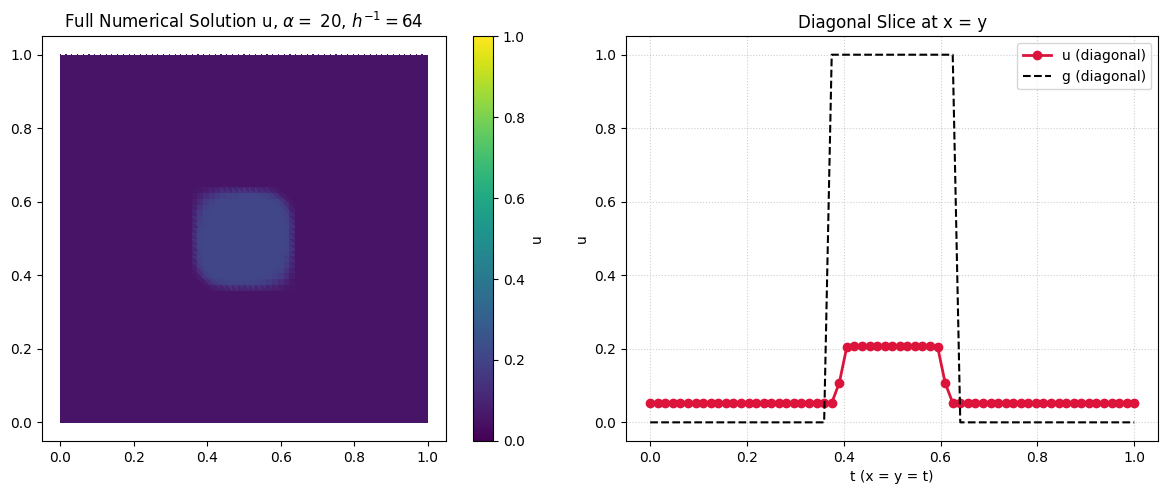

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Setup mesh
Nx, Ny = 64,64
h = min(1/Nx, 1/Ny)
nodes_2d, elements_2d = generate_mesh_2d(Nx, Ny)
tolerance = 1e-6

# 2. Run solver
T = np.sqrt(h)/4
alpha = 20
u_prec, px_prec, py_prec, res_list_prec, g_data_prec = Solve_2D_ROF(
    nodes_2d, elements_2d, alpha=alpha, T=T, noise_level=0.0, max_its=1000
)

# 3. Extract diagonal slice where x = y
diag_indices = np.where(np.abs(nodes_2d[:, 0] - nodes_2d[:, 1]) < tolerance)[0]
sort_idx = diag_indices[np.argsort(nodes_2d[diag_indices, 0])]
t_coords = nodes_2d[sort_idx, 0]
u_slice_diag = u_prec[sort_idx]
clean_slice_diag = np.where((0.375 <= t_coords) & (t_coords <= 0.625), 1.0, 0.0)

# 4. Plotting
plt.figure(figsize=(12, 5))

# Left subplot: 2D visualization with fixed O(1) color scale [0.0, 1.0]
plt.subplot(1, 2, 1)
tripcolor = plt.tripcolor(nodes_2d[:, 0], nodes_2d[:, 1], elements_2d, u_prec, cmap='viridis', vmin=0.0, vmax=1.0)
plt.colorbar(tripcolor, label='u')
plt.title(fr'Full Numerical Solution u, $\alpha =$ {alpha}, $h^{{-1}} = ${Nx}')
plt.gca().set_aspect('equal')

# Right subplot: 1D diagonal slice comparison (x = y = t)
plt.subplot(1, 2, 2)
plt.plot(t_coords, u_slice_diag, 'o-', color='crimson', label='u (diagonal)', lw=2)
plt.plot(t_coords, clean_slice_diag, 'k--', label='g (diagonal)', lw=1.5)
plt.xlabel('t (x = y = t)')
plt.ylabel('u')
plt.title('Diagonal Slice at x = y')
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend()

plt.tight_layout()
plt.show()

Now let's try with a noisy version of $g$.

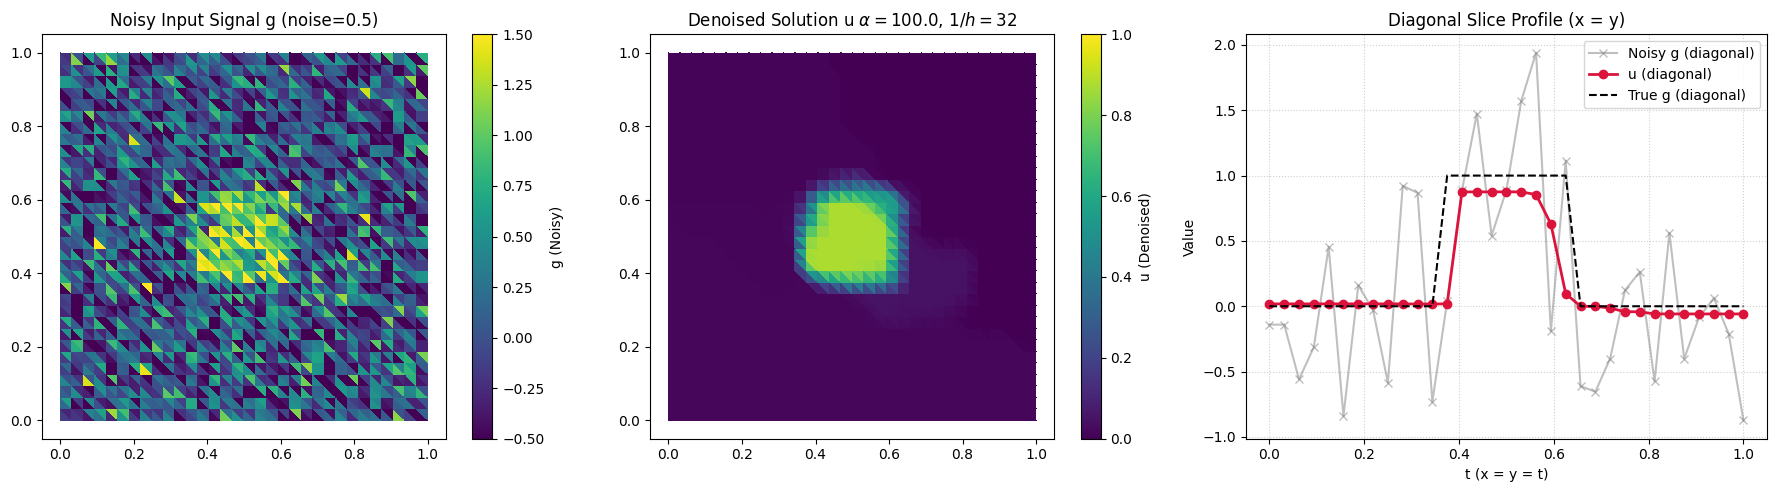

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Setup mesh
Nx, Ny = 8*4, 8*4
h = min(1/Nx, 1/Ny)
nodes_2d, elements_2d = generate_mesh_2d(Nx, Ny)
tolerance = 1e-6

# 2. Run solver with noise
T = np.sqrt(h)/4
alpha = 100.0
noise_level = 0.5
u_prec, px_prec, py_prec, res_list_prec, g_data_prec = Solve_2D_ROF(
    nodes_2d, elements_2d, alpha=alpha, T=T, noise_level=noise_level, max_its=1000
)

# 3. Extract diagonal slices where x = y
diag_indices = np.where(np.abs(nodes_2d[:, 0] - nodes_2d[:, 1]) < tolerance)[0]
sort_idx = diag_indices[np.argsort(nodes_2d[diag_indices, 0])]
t_coords = nodes_2d[sort_idx, 0]
u_slice_diag = u_prec[sort_idx]
clean_slice_diag = np.where((0.375 <= t_coords) & (t_coords <= 0.625), 1.0, 0.0)

# To get a slice of cell-centered g values, find elements intersected by the diagonal
g_slice_diag = []
for t_val in t_coords:
    # Find element containing (t_val, t_val)
    found = False
    for e_idx, elem in enumerate(elements_2d):
        coords = nodes_2d[elem]
        min_x, max_x = np.min(coords[:, 0]), np.max(coords[:, 0])
        min_y, max_y = np.min(coords[:, 1]), np.max(coords[:, 1])
        if min_x - 1e-9 <= t_val <= max_x + 1e-9 and min_y - 1e-9 <= t_val <= max_y + 1e-9:
            g_slice_diag.append(g_data_prec[e_idx])
            found = True
            break
    if not found:
        g_slice_diag.append(0.0)
g_slice_diag = np.array(g_slice_diag)

# 4. Plotting (Three panel layout: Noisy g 2D, Denoised u 2D, and 1D slice comparison)
plt.figure(figsize=(18, 5))

# Left subplot: 2D Noisy Input g
plt.subplot(1, 3, 1)
tripcolor_g = plt.tripcolor(nodes_2d[:, 0], nodes_2d[:, 1], elements_2d, g_data_prec, cmap='viridis', vmin=-0.5, vmax=1.5)
plt.colorbar(tripcolor_g, label='g (Noisy)')
plt.title(f'Noisy Input Signal g (noise={noise_level})')
plt.gca().set_aspect('equal')

# Middle subplot: 2D Denoised Solution u
plt.subplot(1, 3, 2)
tripcolor_u = plt.tripcolor(nodes_2d[:, 0], nodes_2d[:, 1], elements_2d, u_prec, cmap='viridis', vmin=0.0, vmax=1.0)
plt.colorbar(tripcolor_u, label='u (Denoised)')
plt.title(fr'Denoised Solution u $\alpha = {alpha}$, $1/h = {Nx}$')
plt.gca().set_aspect('equal')

# Right subplot: 1D Diagonal Slice Comparison (x = y = t)
plt.subplot(1, 3, 3)
plt.plot(t_coords, g_slice_diag, 'x-', color='gray', alpha=0.5, label='Noisy g (diagonal)')
plt.plot(t_coords, u_slice_diag, 'o-', color='crimson', label='u (diagonal)', lw=2)
plt.plot(t_coords, clean_slice_diag, 'k--', label='True g (diagonal)', lw=1.5)
plt.xlabel('t (x = y = t)')
plt.ylabel('Value')
plt.title('Diagonal Slice Profile (x = y)')
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend()

plt.tight_layout()
plt.show()

### 2D Rudin-Osher-Fatemi (ROF) Functional Evaluation

The ROF functional we are minimizing is defined as:

$$E(u) = \int_{\Omega} |\nabla u| \, dx + \frac{\alpha}{2} \int_{\Omega} (u - g)^2 \, dx$$

We make a function to return $E(u)$, which will serve to give error estimamtes

In [ ]:
import torch
import numpy as np

def calculate_2d_rof(nodes, elements, u_np, g_np, alpha):
    """
    Calculates the discrete Rudin-Osher-Fatemi (ROF) functional on the 2D triangular mesh.

    Parameters:
    nodes : ndarray of shape (num_nodes, 2)
    elements : ndarray of shape (num_elements, 3)
    u_np : ndarray of shape (num_nodes,), primal solution u (nodal P1 representation)
    g_np : ndarray of shape (num_elements,), input image/signal g (cell-wise P0 representation)
    alpha : float, data fidelity weight parameter
    """
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    # Convert inputs to PyTorch tensors
    nodes_t = torch.tensor(nodes, dtype=torch.float64, device=device)
    elem_t = torch.tensor(elements, dtype=torch.long, device=device)
    u = torch.tensor(u_np, dtype=torch.float64, device=device)
    g = torch.tensor(g_np, dtype=torch.float64, device=device)

    # 1. Compute Element Areas
    coords = nodes_t[elem_t]
    v1 = coords[:, 1] - coords[:, 0]
    v2 = coords[:, 2] - coords[:, 0]
    areas = 0.5 * torch.abs(v1[:, 0] * v2[:, 1] - v1[:, 1] * v2[:, 0])

    # 2. Compute Total Variation (TV) term: \int |\nabla u| dx
    # Gradient coefficients
    b = torch.stack([
        coords[:, 1, 1] - coords[:, 2, 1],
        coords[:, 2, 1] - coords[:, 0, 1],
        coords[:, 0, 1] - coords[:, 1, 1]
    ], dim=1) / (2.0 * areas.unsqueeze(1))

    c = torch.stack([
        coords[:, 2, 0] - coords[:, 1, 0],
        coords[:, 0, 0] - coords[:, 2, 0],
        coords[:, 1, 0] - coords[:, 0, 0]
    ], dim=1) / (2.0 * areas.unsqueeze(1))

    # Element-wise gradient vectors
    u_elem = u[elem_t] # shape (num_elements, 3)
    ux = torch.sum(b * u_elem, dim=1)
    uy = torch.sum(c * u_elem, dim=1)

    grad_magnitude = torch.sqrt(ux**2 + uy**2)
    tv_energy = torch.sum(grad_magnitude * areas).item()

    # 3. Compute Data Fidelity term: (alpha / 2) * \int (u - g)^2 dx
    # We project the nodal value u to cell centroids by taking the average of its 3 vertices
    u_cell_avg = torch.mean(u_elem, dim=1)
    fidelity_energy = 0.5 * alpha * torch.sum(((u_cell_avg - g)**2) * areas).item()

    total_energy = tv_energy + fidelity_energy


    return total_energy, tv_energy, fidelity_energy

### Convergence Study of the ROF Functional Energy

We perform a convergence study by refining the mesh size $h = N^{-1}$. For each mesh, we generate the structured triangular grid, run the preconditioned Chambolle-Pock solver, and compute the total ROF functional energy of the converged solution. We just print the values. We plot later.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import torch

# Define the grid resolutions
N_values = [32, 64,128, 256]
energies_study = []

alpha_study = 100

# 1. Run the solver and compute the energy for each resolution
for N_val in N_values:
    h_val = 1.0 / N_val
    T_val = np.sqrt(h_val) / 4.0
    nodes_study, elements_study = generate_mesh_2d(N_val, N_val)


    u_res, _, _, _, g_res = Solve_2D_ROF(
        nodes_study, elements_study, alpha=alpha_study, T=T_val, noise_level=0.0, max_its=3000, eps_stop=1e-6
    )

    total_e, _, _ = calculate_2d_rof(nodes_study, elements_study, u_res, g_res, alpha=alpha_study)
    energies_study.append(total_e)
    print(f"Solution with N = {N_val} Completed Successfully: I = {total_e}")

Solution with N = 32 Completed Successfully: I = 0.8509657011567235
Solution with N = 48 Completed Successfully: I = 0.8527621929668434


KeyboardInterrupt: 

##Now, let's try to clean up some images:

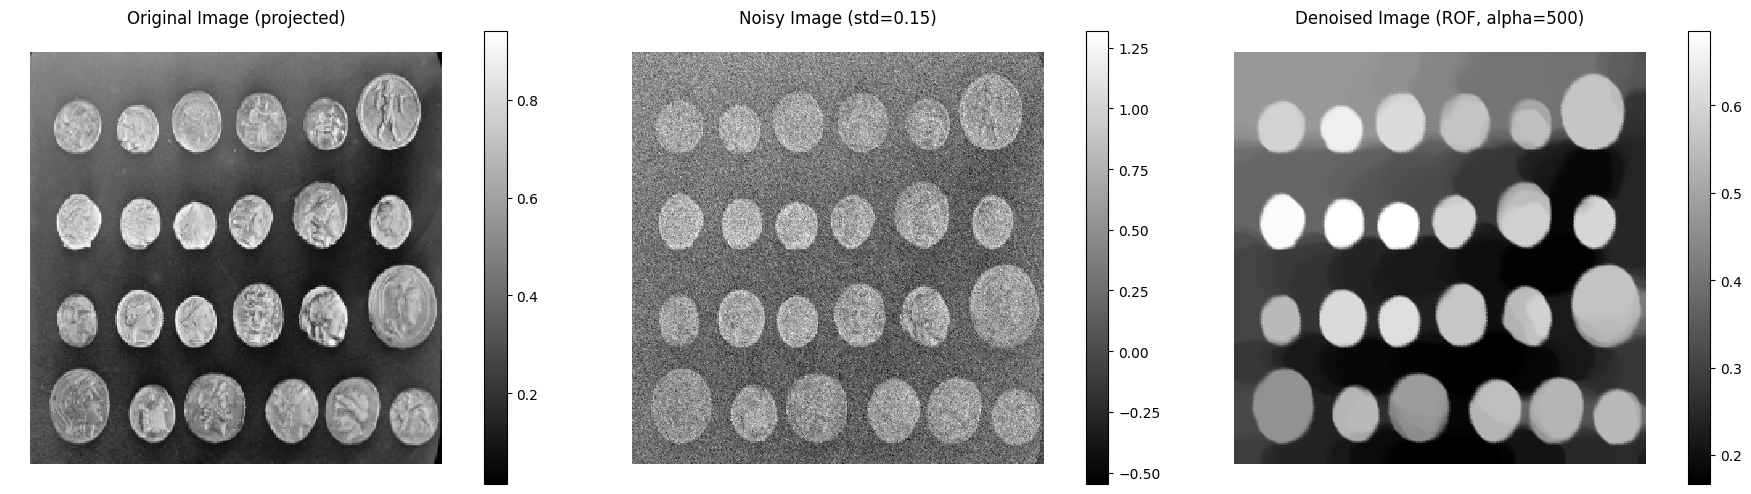

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import torch
from skimage import data
from skimage.transform import resize

# 1. Load an example image and resize it for our mesh
Nx, Ny = 256, 256
image_raw = data.coins().astype(np.float64) / 255.0
image_resized = resize(image_raw, (Nx, Ny), anti_aliasing=True)

# 2. Generate the corresponding structured 2D triangular mesh
nodes_img, elements_img = generate_mesh_2d(Nx, Ny)

# 3. Associate pixel values with triangles (P0 cells)
# Each pixel (i, j) corresponds to two triangles in the corresponding rectangle
g_original = np.zeros(len(elements_img))
for j in range(Ny):
    for i in range(Nx):
        val = image_resized[Ny - 1 - j, i]  # Flip Y-axis for spatial consistency
        idx_t1 = 2 * (j * Nx + i)
        idx_t2 = idx_t1 + 1
        g_original[idx_t1] = val
        g_original[idx_t2] = val

# 4. Add Gaussian noise to the image on the mesh
noise_std = 0.15
np.random.seed(42)
g_noisy = g_original + np.random.normal(0.0, noise_std, len(g_original))

# 5. Define a temporary function to inject this noisy image into our solver
def get_g_custom(nodes, elements, noise_level=0.0):
    return g_noisy

original_get_g_2d = globals().get('get_g_2d')
globals()['get_g_2d'] = get_g_custom

# 6. Execute the 2D ROF solver
h = 1.0 / Nx
T_step = np.sqrt(h) / 4.0
alpha_param = 500

try:
    u_denoised, _, _, _, _ = Solve_2D_ROF(
        nodes_img, elements_img, alpha=alpha_param, T=T_step, noise_level=0.0, max_its=800, eps_stop=1e-5
    )
finally:
    # Restore the original global g function
    if original_get_g_2d is not None:
        globals()['get_g_2d'] = original_get_g_2d

# 7. Display results (Original, Noisy, Denoised)
plt.figure(figsize=(18, 5))

plt.subplot(1, 3, 1)
tripcolor_orig = plt.tripcolor(nodes_img[:, 0], nodes_img[:, 1], elements_img, facecolors=g_original, cmap='gray', edgecolors='none')
plt.colorbar(tripcolor_orig, fraction=0.046, pad=0.04)
plt.title("Original Image (projected)")
plt.gca().set_aspect('equal')
plt.axis('off')

plt.subplot(1, 3, 2)
tripcolor_noisy = plt.tripcolor(nodes_img[:, 0], nodes_img[:, 1], elements_img, facecolors=g_noisy, cmap='gray', edgecolors='none')
plt.colorbar(tripcolor_noisy, fraction=0.046, pad=0.04)
plt.title(f"Noisy Image (std={noise_std})")
plt.gca().set_aspect('equal')
plt.axis('off')

plt.subplot(1, 3, 3)
tripcolor_denoised = plt.tripcolor(nodes_img[:, 0], nodes_img[:, 1], elements_img, u_denoised, cmap='gray', edgecolors='none')
plt.colorbar(tripcolor_denoised, fraction=0.046, pad=0.04)
plt.title(f"Denoised Image (ROF, alpha={alpha_param})")
plt.gca().set_aspect('equal')
plt.axis('off')

plt.tight_layout()
plt.show()

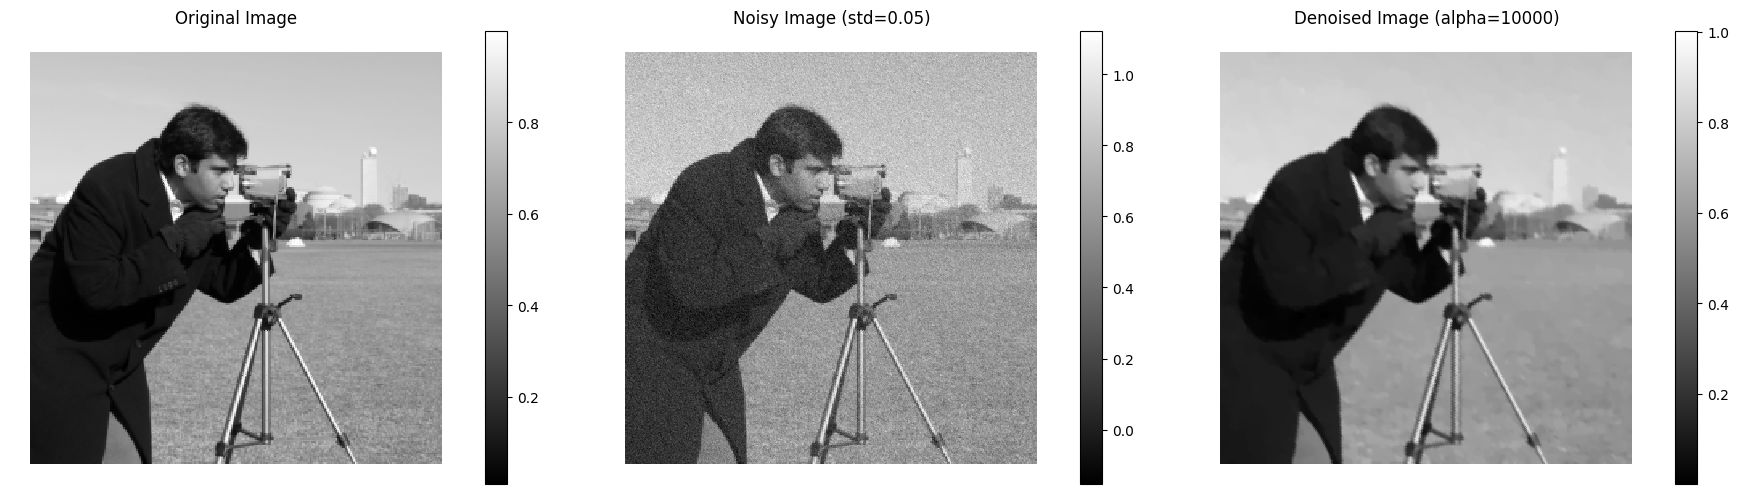

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import torch
from skimage import data
from skimage.transform import resize

# 1. Load the lighthouse image and resize it
Nx, Ny = 256, 256
# Some environments have data.lighthouse(), otherwise we use a fallback image (like data.camera())
try:
    image_raw = data.lighthouse().astype(np.float64) / 255.0
    # If the image is in color, convert it to grayscale
    if image_raw.ndim == 3:
        image_raw = np.mean(image_raw, axis=2)
except AttributeError:
    # Fallback to data.camera if lighthouse is not directly available
    image_raw = data.camera().astype(np.float64) / 255.0

image_resized = resize(image_raw, (Nx, Ny), anti_aliasing=True)

# 2. Generate the corresponding structured 2D triangular mesh
nodes_lh, elements_lh = generate_mesh_2d(Nx, Ny)

# 3. Associate pixel values with triangles (P0 cells)
g_original_lh = np.zeros(len(elements_lh))
for j in range(Ny):
    for i in range(Nx):
        val = image_resized[Ny - 1 - j, i]
        idx_t1 = 2 * (j * Nx + i)
        idx_t2 = idx_t1 + 1
        g_original_lh[idx_t1] = val
        g_original_lh[idx_t2] = val

# 4. Add Gaussian noise
noise_std = 0.05
np.random.seed(42)
g_noisy_lh = g_original_lh + np.random.normal(0.0, noise_std, len(g_original_lh))

# 5. Define temporary function to inject this noisy image into our solver
def get_g_custom_lh(nodes, elements, noise_level=0.0):
    return g_noisy_lh

original_get_g_2d = globals().get('get_g_2d')
globals()['get_g_2d'] = get_g_custom_lh

# 6. Execute the 2D ROF solver
h = 1.0 / Nx
T_step = np.sqrt(h) / 4.0
alpha_param = 10000

try:
    u_denoised_lh, _, _, _, _ = Solve_2D_ROF(
        nodes_lh, elements_lh, alpha=alpha_param, T=T_step, noise_level=0.0, max_its=800, eps_stop=1e-5
    )
finally:
    # Restore the original global g function
    if original_get_g_2d is not None:
        globals()['get_g_2d'] = original_get_g_2d

# 7. Display results (Original, Noisy, Denoised)
plt.figure(figsize=(18, 5))

plt.subplot(1, 3, 1)
tripcolor_orig = plt.tripcolor(nodes_lh[:, 0], nodes_lh[:, 1], elements_lh, facecolors=g_original_lh, cmap='gray', edgecolors='none')
plt.colorbar(tripcolor_orig, fraction=0.046, pad=0.04)
plt.title("Original Image")
plt.gca().set_aspect('equal')
plt.axis('off')

plt.subplot(1, 3, 2)
tripcolor_noisy = plt.tripcolor(nodes_lh[:, 0], nodes_lh[:, 1], elements_lh, facecolors=g_noisy_lh, cmap='gray', edgecolors='none')
plt.colorbar(tripcolor_noisy, fraction=0.046, pad=0.04)
plt.title(f"Noisy Image (std={noise_std})")
plt.gca().set_aspect('equal')
plt.axis('off')

plt.subplot(1, 3, 3)
tripcolor_denoised = plt.tripcolor(nodes_lh[:, 0], nodes_lh[:, 1], elements_lh, u_denoised_lh, cmap='gray', edgecolors='none')
plt.colorbar(tripcolor_denoised, fraction=0.046, pad=0.04)
plt.title(f"Denoised Image (alpha={alpha_param})")
plt.gca().set_aspect('equal')
plt.axis('off')

plt.tight_layout()
plt.show()

## We now use a quadurature rule to allow error analysis of more general $g$

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import torch

def is_inside_rotated_square(pts, center=(0.5, 0.5), side=0.35, angle_deg=30.0):
    """
    Checks if points are inside a rotated square.
    pts: ndarray of shape (..., 2)
    """
    theta = np.radians(angle_deg)
    cos_t, sin_t = np.cos(theta), np.sin(theta)
    R = np.array([[cos_t, -sin_t], [sin_t, cos_t]])

    pts_shifted = pts - center
    pts_rot = pts_shifted @ R

    half_side = side / 2.0
    inside = (np.abs(pts_rot[..., 0]) <= half_side) & (np.abs(pts_rot[..., 1]) <= half_side)
    return inside.astype(np.float64)

def get_g_rotated_square_with_smooth_exact(nodes, elements, center=(0.5, 0.5), side=0.35, angle_deg=30.0):
    """
    Computes the exact volume average of the target g function on each triangle.
    g(x, y) = Indicator(RotatedSquare) + sin(2 * pi * x) * cos(2 * pi * y) [smooth term]
    using a high-order 12-point symmetric quadrature rule.
    """
    bary = np.array([
        [0.05054722831703, 0.05054722831703, 0.89890554336594],
        [0.05054722831703, 0.89890554336594, 0.05054722831703],
        [0.89890554336594, 0.05054722831703, 0.05054722831703],
        [0.11564095133645, 0.44217952433178, 0.44217952433178],
        [0.44217952433178, 0.11564095133645, 0.44217952433178],
        [0.44217952433178, 0.44217952433178, 0.11564095133645],
        [0.00631168434773, 0.49684415782613, 0.49684415782614],
        [0.00631168434773, 0.49684415782614, 0.49684415782614],
        [0.49684415782613, 0.00631168434773, 0.49684415782614],
        [0.49684415782614, 0.00631168434773, 0.49684415782613],
        [0.49684415782613, 0.49684415782614, 0.00631168434773],
        [0.49684415782614, 0.49684415782613, 0.00631168434773]
    ])
    w = np.array([
        0.05151515151515, 0.05151515151515, 0.05151515151515,
        0.11211211211211, 0.11211211211211, 0.11211211211211,
        0.07633121516625, 0.07633121516625, 0.07633121516625,
        0.07633121516625, 0.07633121516625, 0.07633121516625
    ]) / 2.0

    num_elements = len(elements)
    g_face = np.zeros(num_elements)

    for e_idx, elem in enumerate(elements):
        tri_nodes = nodes[elem]
        quad_pts = bary @ tri_nodes

        indicator_vals = is_inside_rotated_square(quad_pts, center, side, angle_deg)
        smooth_vals = np.sin(2.0 * np.pi * quad_pts[:, 0]) * np.cos(2.0 * np.pi * quad_pts[:, 1])

        total_vals = indicator_vals + smooth_vals
        g_face[e_idx] = np.sum(2.0 * w * total_vals)

    return g_face

def calculate_2d_rof(nodes, elements, u_np, g_np, alpha, g_functional_func=None):
    """
    Calculates the discrete Rudin-Osher-Fatemi (ROF) functional on the 2D triangular mesh.
    If g_functional_func is provided, we evaluate the L2 fidelity term continuously
    using our 12-point symmetric quadrature rule, accounting for non-constant target functions g.
    """
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    nodes_t = torch.tensor(nodes, dtype=torch.float64, device=device)
    elem_t = torch.tensor(elements, dtype=torch.long, device=device)
    u = torch.tensor(u_np, dtype=torch.float64, device=device)

    coords = nodes_t[elem_t]
    v1 = coords[:, 1] - coords[:, 0]
    v2 = coords[:, 2] - coords[:, 0]
    areas = 0.5 * torch.abs(v1[:, 0] * v2[:, 1] - v1[:, 1] * v2[:, 0])

    b = torch.stack([
        coords[:, 1, 1] - coords[:, 2, 1],
        coords[:, 2, 1] - coords[:, 0, 1],
        coords[:, 0, 1] - coords[:, 1, 1]
    ], dim=1) / (2.0 * areas.unsqueeze(1))

    c = torch.stack([
        coords[:, 2, 0] - coords[:, 1, 0],
        coords[:, 0, 0] - coords[:, 2, 0],
        coords[:, 1, 0] - coords[:, 0, 0]
    ], dim=1) / (2.0 * areas.unsqueeze(1))

    u_elem = u[elem_t]
    ux = torch.sum(b * u_elem, dim=1)
    uy = torch.sum(c * u_elem, dim=1)

    grad_magnitude = torch.sqrt(ux**2 + uy**2)
    tv_energy = torch.sum(grad_magnitude * areas).item()

    if g_functional_func is not None:
        # High-order 12-point symmetric quadrature to integrate (u_h(x,y) - g(x,y))^2
        bary = np.array([
            [0.05054722831703, 0.05054722831703, 0.89890554336594],
            [0.05054722831703, 0.89890554336594, 0.05054722831703],
            [0.89890554336594, 0.05054722831703, 0.05054722831703],
            [0.11564095133645, 0.44217952433178, 0.44217952433178],
            [0.44217952433178, 0.11564095133645, 0.44217952433178],
            [0.44217952433178, 0.44217952433178, 0.11564095133645],
            [0.00631168434773, 0.49684415782613, 0.49684415782614],
            [0.00631168434773, 0.49684415782614, 0.49684415782614],
            [0.49684415782613, 0.00631168434773, 0.49684415782614],
            [0.49684415782614, 0.00631168434773, 0.49684415782613],
            [0.49684415782613, 0.49684415782614, 0.00631168434773],
            [0.49684415782614, 0.49684415782613, 0.00631168434773]
        ])
        w = np.array([
            0.05151515151515, 0.05151515151515, 0.05151515151515,
            0.11211211211211, 0.11211211211211, 0.11211211211211,
            0.07633121516625, 0.07633121516625, 0.07633121516625,
            0.07633121516625, 0.07633121516625, 0.07633121516625
        ]) / 2.0

        fidelity_energy = 0.0
        u_np_array = u.cpu().numpy()
        for e_idx in range(len(elements)):
            tri_nodes = nodes[elements[e_idx]]
            quad_pts = bary @ tri_nodes

            # Evaluate linear FEM function u_h at quad points
            u_vals = bary @ u_np_array[elements[e_idx]]

            # Evaluate analytical target function g at quad points
            g_vals = g_functional_func(quad_pts)

            elem_integral = np.sum(2.0 * w * (u_vals - g_vals)**2) * areas[e_idx].item()
            fidelity_energy += 0.5 * alpha * elem_integral
    else:
        g = torch.tensor(g_np, dtype=torch.float64, device=device)
        u_cell_avg = torch.mean(u_elem, dim=1)
        fidelity_energy = 0.5 * alpha * torch.sum(((u_cell_avg - g)**2) * areas).item()

    return tv_energy + fidelity_energy, tv_energy, fidelity_energy

Completed mesh N =   16 | ROF Energy = 4.90861741
Completed mesh N =   32 | ROF Energy = 4.84145394
Completed mesh N =   64 | ROF Energy = 4.82222641
Completed mesh N =  128 | ROF Energy = 4.80015032
Completed mesh N =  256 | ROF Energy = 4.78171248


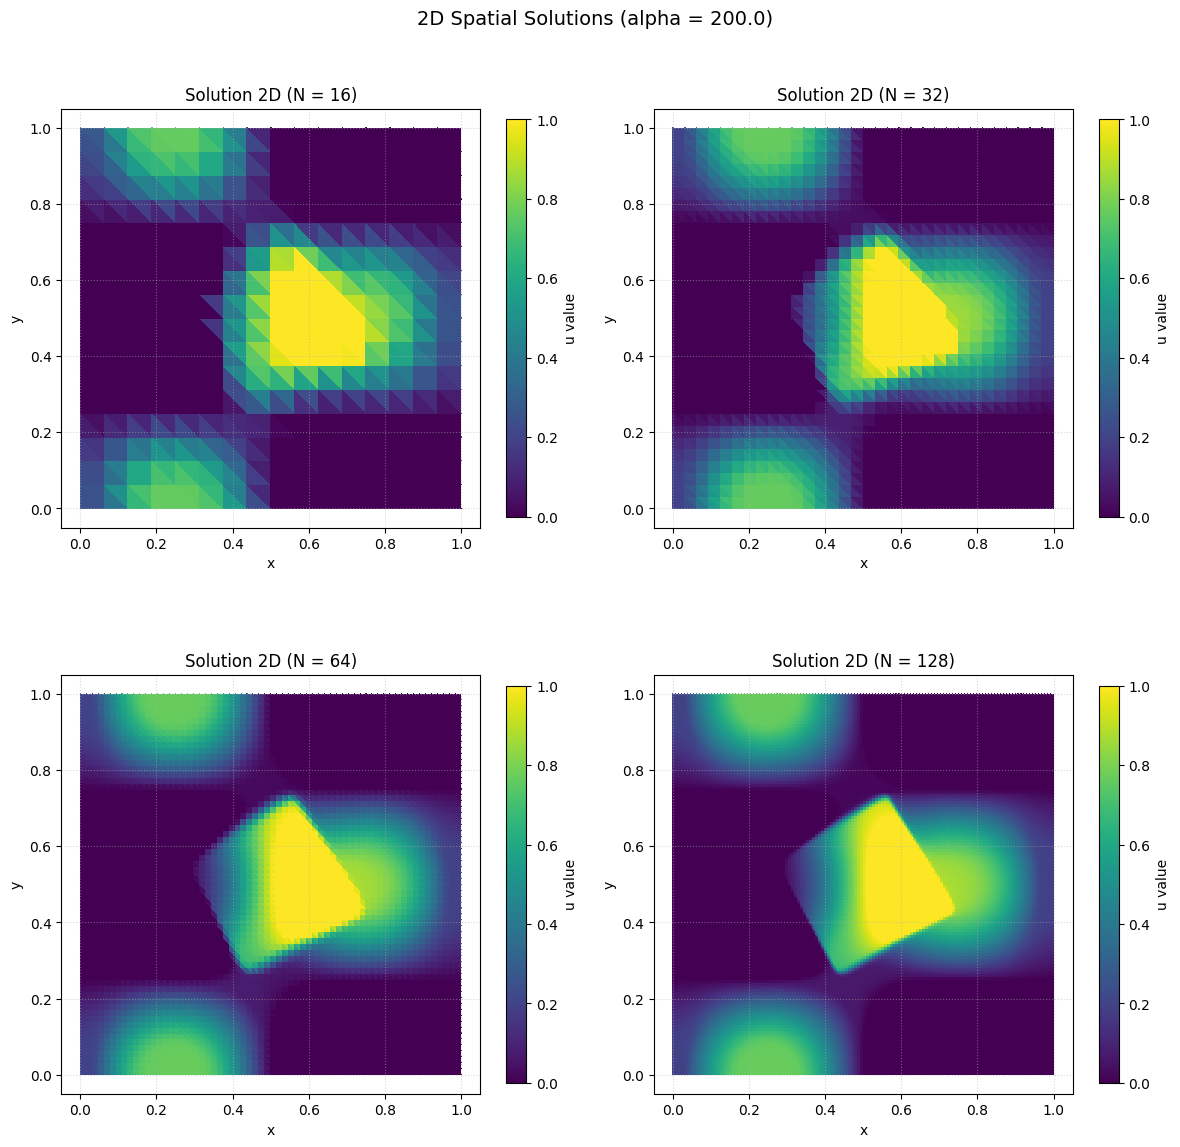

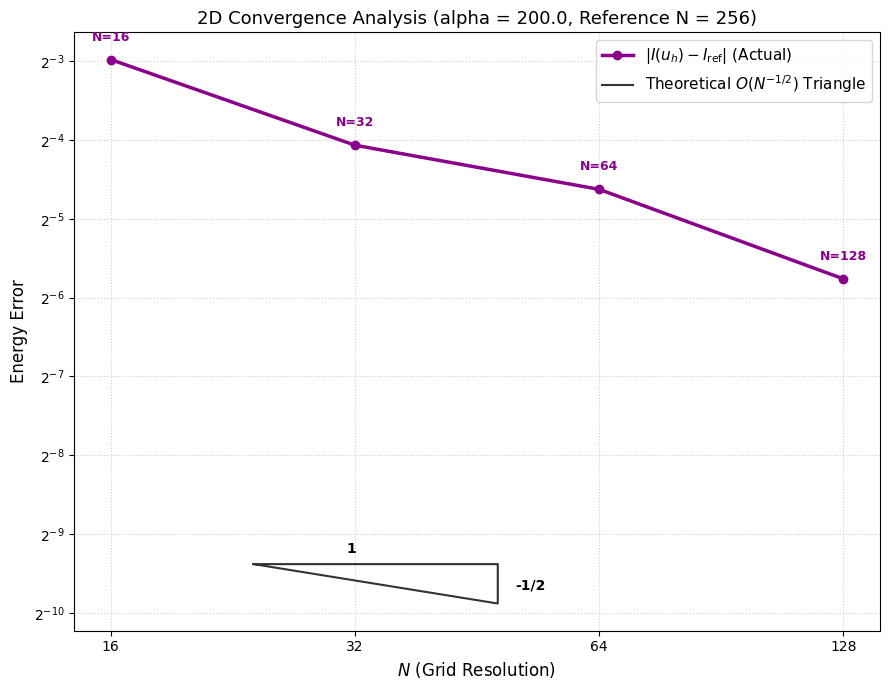

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import torch

# Consolidated Convergence Study with N_study_list capped at N = 256
N_study_list = [16, 32, 64, 128, 256]
alpha_study = 200.0

def get_g_2d_custom_rotated(nodes, elements, noise_level=0.0):
    return get_g_rotated_square_with_smooth_exact(nodes, elements, center=(0.5, 0.5), side=0.35, angle_deg=30.0)

# Temporarily swap standard get_g_2d
original_get_g_2d = globals().get('get_g_2d')
globals()['get_g_2d'] = get_g_2d_custom_rotated

solutions_dict = {}
energies_study = []

try:
    # 1. Run solvers for all resolutions
    for N_val in N_study_list:
        h_val = 1.0 / N_val
        T_val = np.sqrt(h_val) / 4.0
        nodes_study, elements_study = generate_mesh_2d(N_val, N_val)

        # Solve 2D ROF with looser eps_stop to prevent hang/interruption
        u_res, _, _, _, g_res = Solve_2D_ROF(
            nodes_study, elements_study, alpha=alpha_study, T=T_val, noise_level=0.0, max_its=1000, eps_stop=1e-5
        )

        # Calculate and record energy
        total_e, _, _ = calculate_2d_rof(nodes_study, elements_study, u_res, g_res, alpha=alpha_study)
        energies_study.append(total_e)
        print(f"Completed mesh N = {N_val:4d} | ROF Energy = {total_e:.8f}")

        # Save specifically the 4 solutions for the 2x2 grid (16, 32, 64, 128)
        if N_val in [16, 32, 64, 128]:
            solutions_dict[N_val] = (nodes_study, elements_study, u_res)

    # 2. Plot the 4 solutions in a 2x2 layout
    plot_N_vals = [16, 32, 64, 128]
    fig, axs = plt.subplots(2, 2, figsize=(12, 12))
    for idx, N_val in enumerate(plot_N_vals):
        ax = axs[idx // 2, idx % 2]
        nodes_study, elements_study, u_res = solutions_dict[N_val]
        tripcolor = ax.tripcolor(nodes_study[:, 0], nodes_study[:, 1], elements_study, u_res, cmap='viridis', vmin=0.0, vmax=1.0)
        fig.colorbar(tripcolor, ax=ax, label='u value', shrink=0.7)
        ax.set_title(f'Solution 2D (N = {N_val})', fontsize=12)
        ax.set_xlabel('x')
        ax.set_ylabel('y')
        ax.set_aspect('equal', adjustable='box')
        ax.grid(True, linestyle=':', alpha=0.5)

    plt.suptitle(f'2D Spatial Solutions (alpha = {alpha_study})', fontsize=14, y=0.98)
    plt.tight_layout()
    plt.show()

    if original_get_g_2d is not None:
        globals()['get_g_2d'] = original_get_g_2d

Completed N =  16 | ROF Energy I(u) = 4.00128533
Completed N =  32 | ROF Energy I(u) = 3.89442769
Completed N =  64 | ROF Energy I(u) = 3.87255682
Completed N = 128 | ROF Energy I(u) = 3.86643758


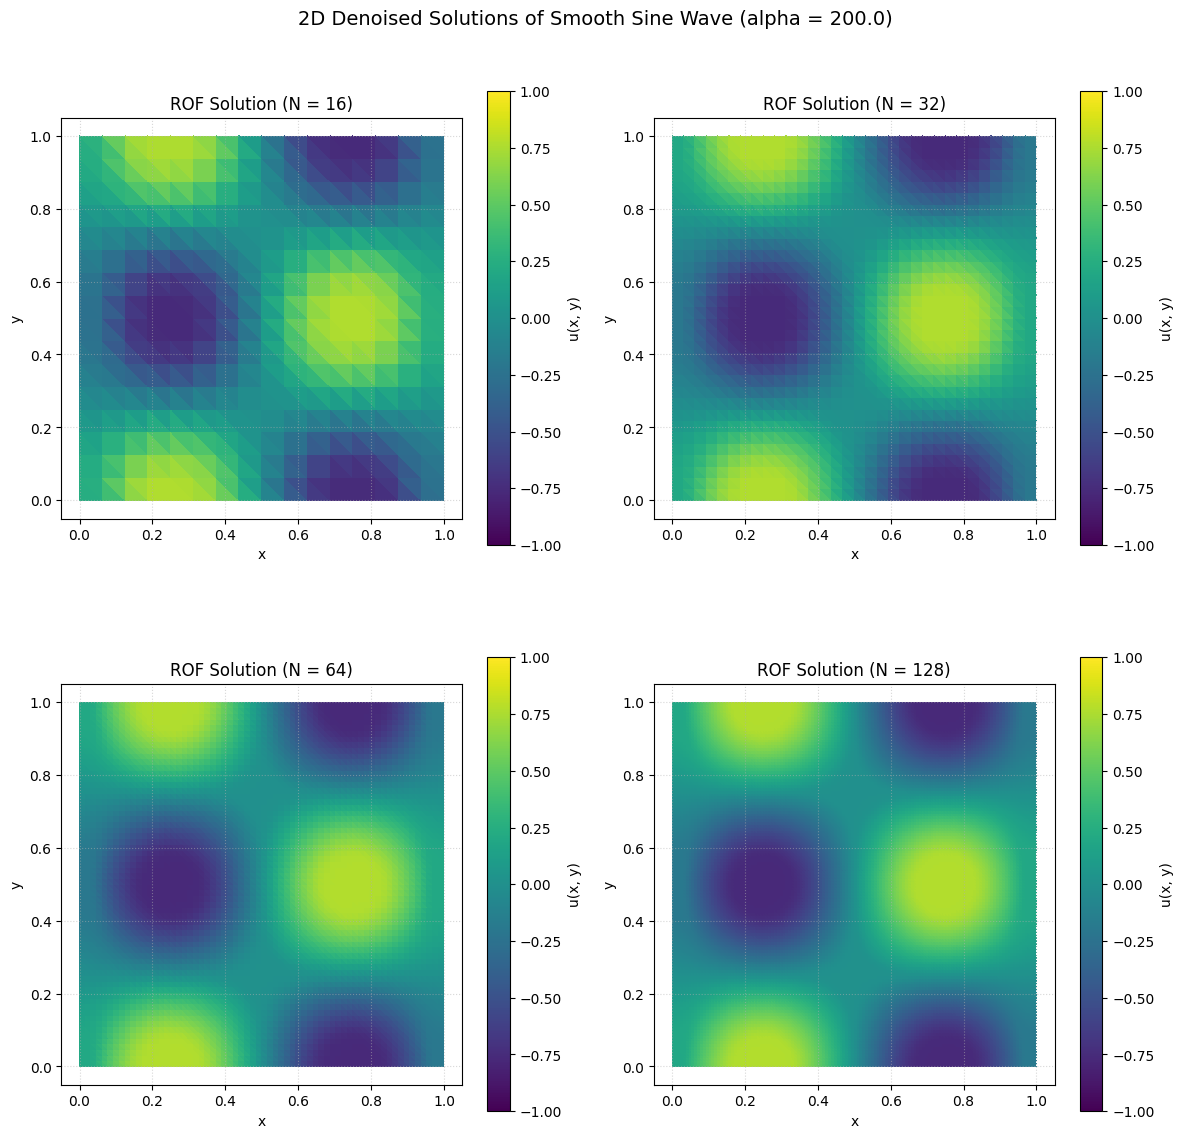

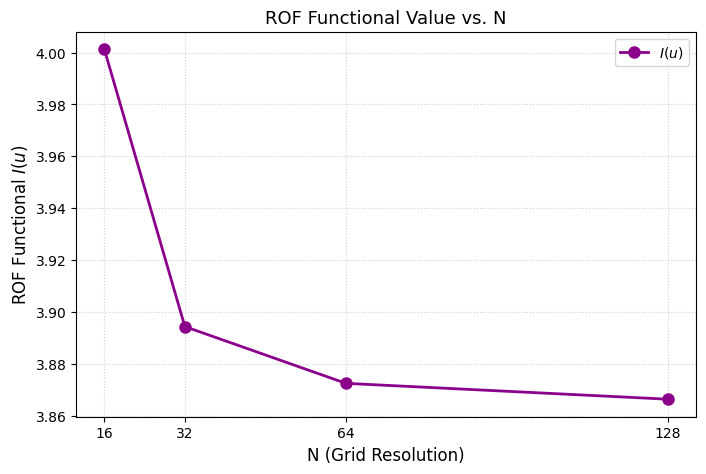

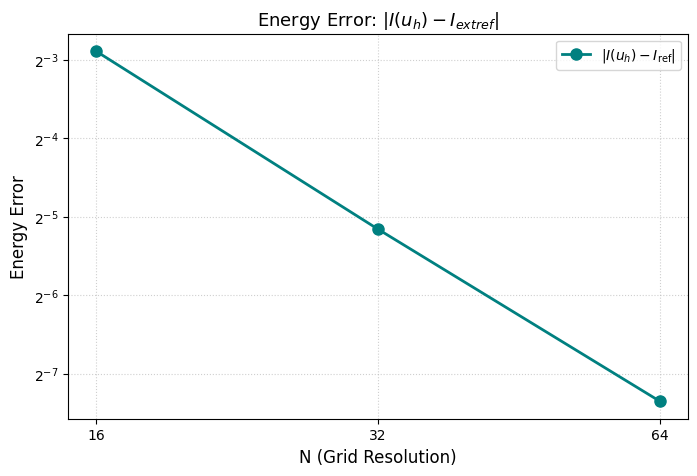

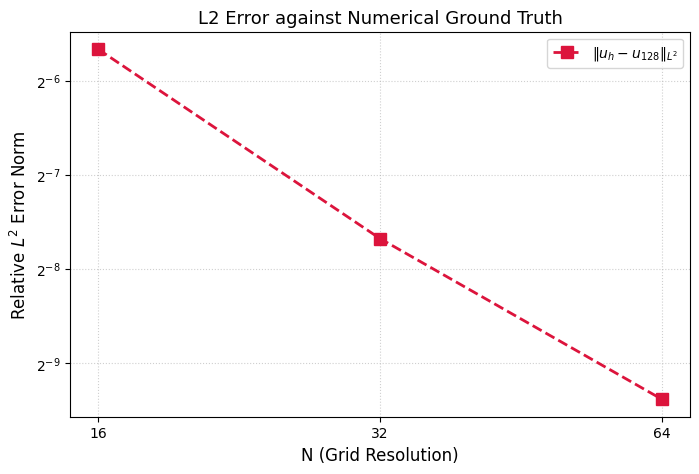

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import scipy.interpolate

# 1. Define the exact smooth sine wave signal function
def analytical_g_smooth(pts):
    return np.sin(2.0 * np.pi * pts[:, 0]) * np.cos(2.0 * np.pi * pts[:, 1])

# Configure global study parameters capped at N = 128
N_vals = [16, 32, 64, 128]
alpha_study = 200.0
solutions = {}
energies = []

# Swap the global generator to use our smooth function
original_get_g_2d = globals().get('get_g_2d')
globals()['get_g_2d'] = get_g_smooth_only

try:
    for N in N_vals:
        h = 1.0 / N
        T = np.sqrt(h) / 4.0
        nodes_study, elements_study = generate_mesh_2d(N, N)

        # Solve 2D ROF
        u_res, _, _, _, g_res = Solve_2D_ROF(
            nodes_study, elements_study, alpha=alpha_study, T=T, noise_level=0.0, max_its=1200, eps_stop=1e-6
        )

        # Compute high-order quadrature functional evaluation I(u)
        total_e, _, _ = calculate_2d_rof(
            nodes_study, elements_study, u_res, g_res, alpha=alpha_study, g_functional_func=analytical_g_smooth
        )

        solutions[N] = (nodes_study, elements_study, u_res)
        energies.append(total_e)
        print(f"Completed N = {N:3d} | ROF Energy I(u) = {total_e:.8f}")

finally:
    # Restore system generator
    if original_get_g_2d is not None:
        globals()['get_g_2d'] = original_get_g_2d

# 2. Plotting spatial profiles in a 2x2 grid layout (Only displaying N <= 128)
plot_N_vals = [16, 32, 64, 128]
fig, axs = plt.subplots(2, 2, figsize=(12, 12))

for idx, N in enumerate(plot_N_vals):
    row, col = idx // 2, idx % 2
    ax = axs[row, col]
    nd, el, u_sol = solutions[N]
    trip = ax.tripcolor(nd[:, 0], nd[:, 1], el, u_sol, cmap='viridis', vmin=-1.0, vmax=1.0)
    fig.colorbar(trip, ax=ax, label='u(x, y)', shrink=0.8)
    ax.set_title(f'ROF Solution (N = {N})', fontsize=12)
    ax.set_xlabel('x')
    ax.set_ylabel('y')
    ax.set_aspect('equal', adjustable='box')
    ax.grid(True, linestyle=':', alpha=0.5)

plt.suptitle(f'2D Denoised Solutions of Smooth Sine Wave (alpha = {alpha_study})', fontsize=14, y=0.98)
plt.tight_layout()
plt.show()

# 3. Plot ROF Energy I(u) against N (Linear Scale as requested)
plt.figure(figsize=(8, 5))
plt.plot(N_vals, energies, 'o-', color='darkmagenta', lw=2, markersize=8, label=r'$I(u)$')
plt.xlabel('N (Grid Resolution)', fontsize=12)
plt.ylabel('ROF Functional $I(u)$', fontsize=12)
plt.title('ROF Functional Value vs. N', fontsize=13)
plt.grid(True, linestyle=':', alpha=0.6)
plt.xticks(N_vals)
plt.legend()
plt.show()

# 4. Plot Energy Error |I(u) - I_ref| against N on Log-Log with Base 2
ref_N = 128
I_ref = energies[-1]
N_study_vals = np.array(N_vals[:-1])
energy_errors = np.abs(np.array(energies[:-1]) - I_ref)

plt.figure(figsize=(8, 5))
plt.loglog(N_study_vals, energy_errors, 'o-', color='teal', lw=2, markersize=8, label=r'$|I(u_h) - I_{\text{ref}}|$', base=2)
plt.xlabel('N (Grid Resolution)', fontsize=12)
plt.ylabel('Energy Error', fontsize=12)
plt.title('Energy Error: $|I(u_h) - I_{\text{ref}}|$', fontsize=13)
plt.grid(True, which='both', linestyle=':', alpha=0.6)
plt.xscale('log', base=2)
plt.yscale('log', base=2)
plt.xticks(N_study_vals, [str(n) for n in N_study_vals])
plt.legend()
plt.show()

# 5. Plot L^2 Norm of each solution compared to N = 128 reference on Log-Log with Base 2
ref_nd, ref_el, ref_u = solutions[ref_N]
l2_differences = []
for N in N_vals:
    nd, el, u_sol = solutions[N]
    interp = scipy.interpolate.LinearNDInterpolator(nd, u_sol, fill_value=0.0)
    u_projected_on_ref = interp(ref_nd)

    # Compute continuous L^2 difference norm over the reference mesh
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    diff_tensor = torch.tensor(u_projected_on_ref - ref_u, dtype=torch.float64, device=device)
    M_ref = compute_mass_matrix_2d(ref_nd, ref_el, device=device)
    l2_diff = torch.sqrt(torch.dot(diff_tensor, torch.mv(M_ref, diff_tensor))).item()
    l2_differences.append(l2_diff)

# Plot the relative L2 errors (omitting N=128 which is 0 compared to itself for a valid log plot)
plt.figure(figsize=(8, 5))
plt.loglog(N_vals[:-1], l2_differences[:-1], 's--', color='crimson', lw=2, markersize=8, label=r'$\|u_h - u_{128}\|_{L^2}$', base=2)
plt.xlabel('N (Grid Resolution)', fontsize=12)
plt.ylabel('Relative $L^2$ Error Norm', fontsize=12)
plt.title('L2 Error against Numerical Ground Truth', fontsize=13)
plt.grid(True, which='both', linestyle=':', alpha=0.6)
plt.xscale('log', base=2)
plt.yscale('log', base=2)
plt.xticks(N_vals[:-1], [str(n) for n in N_vals[:-1]])
plt.legend()
plt.show()

<>:15: SyntaxWarning: invalid escape sequence '\s'
<>:15: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_18940/3070577876.py:15: SyntaxWarning: invalid escape sequence '\s'
  plt.title("$g(x,y) = \sin(2 \pi x)*\cos(2 \pi y)$ \n(Volume Averages)", fontsize=12)


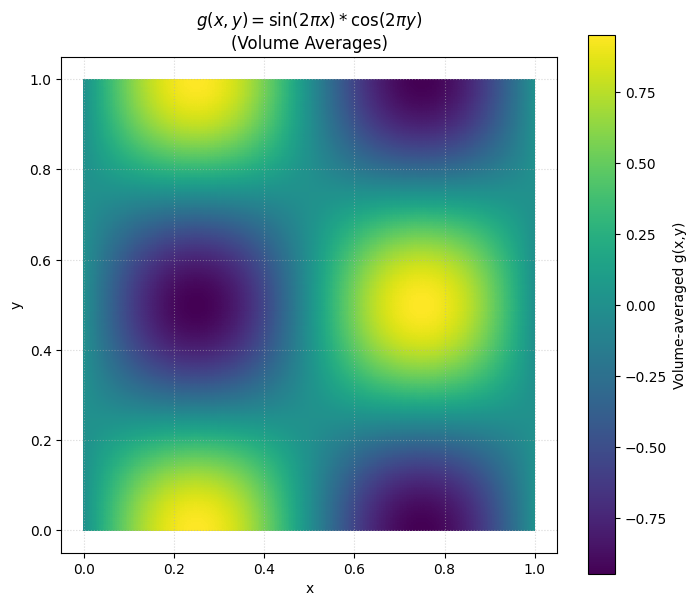

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Generate a 64x64 grid to visualize the smooth input signal g(x,y)
vis_N = 256
vis_nodes, vis_elements = generate_mesh_2d(vis_N, vis_N)

# 2. Compute the exact volume averages of our smooth g
g_smooth_vis = get_g_smooth_only(vis_nodes, vis_elements)

# 3. Plot the smooth input function g
plt.figure(figsize=(8, 7))
tripcolor_g = plt.tripcolor(vis_nodes[:, 0], vis_nodes[:, 1], vis_elements, facecolors=g_smooth_vis, cmap='viridis', edgecolors='none')
plt.colorbar(tripcolor_g, label='Volume-averaged g(x,y)')
plt.title("$g(x,y) = \sin(2 \pi x)*\cos(2 \pi y)$ \n(Volume Averages)", fontsize=12)
plt.xlabel("x")
plt.ylabel("y")
plt.gca().set_aspect('equal')
plt.grid(True, linestyle=':', alpha=0.5)
plt.show()